<a href="https://colab.research.google.com/github/afon6ka-a11y/E-commerce-Sales-Analysis/blob/main/Portfolio_project_1_Kurchenko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import auth
from google.colab import files
from google.cloud import bigquery
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

## **1. Connection to the database in Google BigQuery (DA dataset)**

**Підключення до бази даних в Google BigQuery (DA dataset)**

In [ ]:
# Authentication / Аутентифікація
auth.authenticate_user()

In [ ]:
# Creating a client for BigQuery / Створення клієнта для BigQuery
client = bigquery.Client(project="data-analytics-mate")

## **2. Writing a SQL query in the Python to create a dataset containing all the information required for analysis**

**Написання SQL запиту у Python для створення набору даних, що містить усю необхідну для аналізу інформацію**

In [ ]:
# SQL query / SQL-запит
query = """
WITH
 session_info AS (
   -- All sessions with their parameters / Усі сесії з параметрами
   SELECT
     s.date AS session_date,
     s.ga_session_id AS session_id,
     IF(sp.country = '(not set)', 'Unknown', sp.country)
       AS country,  -- replace (not set) with Unknown
     IF(sp.continent = '(not set)', 'Unknown', sp.continent)
       AS continent,  -- replace (not set) with Unknown
     INITCAP(sp.device) AS device,  -- device name starts with a capital letter
     REPLACE(REPLACE(sp.browser, '<', ''), '>', '')
       AS browser,  -- remove < and >
     IF(sp.mobile_model_name = '<Other>', 'Unknown', sp.mobile_model_name)
       AS mobile_model_name,  -- replace Other with Unknown
     IF(sp.operating_system = '<Other>', 'Unknown', sp.operating_system)
       AS operating_system,  -- replace Other with Unknown
     CASE
       WHEN sp.language IS NULL THEN 'Unknown'
       WHEN sp.language IN ('en-gb', 'en', 'en-ca', 'en-us') THEN 'English'
       WHEN sp.language = 'es-es' THEN 'Spanish'
       WHEN sp.language = 'fr' THEN 'French'
       WHEN sp.language = 'zh' THEN 'Chinese'
       WHEN sp.language = 'de' THEN 'German'
       WHEN sp.language = 'ko' THEN 'Korean'
       END AS language,  -- rename and combine languages
     CASE
       WHEN sp.name = '(organic)' THEN 'Organic'
       WHEN sp.name = '(direct)' THEN 'Direct'
       WHEN sp.name = '(referral)' THEN 'Referral'
       WHEN sp.name = '<Other>' THEN 'Unknown'
       ELSE 'Deleted data'
       END AS traffic_source,  -- rename traffic_source
     sp.channel AS traffic_channel
   FROM `data-analytics-mate.DA.session` AS s
   LEFT JOIN `data-analytics-mate.DA.session_params` AS sp
     ON s.ga_session_id = sp.ga_session_id
 ),
 account_info AS (
   -- Registered users linked to sessions / Зареєстровані користувачі
   SELECT
     acs.ga_session_id,
     a.id AS account_id,
     a.is_verified,
     a.is_unsubscribed
   FROM `data-analytics-mate.DA.account_session` AS acs
   JOIN `data-analytics-mate.DA.account` AS a
     ON acs.account_id = a.id
 ),
 order_info AS (
   -- Orders with product details / Замовлення з даними про товар
   SELECT
     o.ga_session_id,
     p.category AS product_category,
     INITCAP(p.name)
       AS product_name,  -- product name starts with a capital letter
     p.price,
     p.short_description AS product_description
   FROM `data-analytics-mate.DA.order` AS o
   JOIN `data-analytics-mate.DA.product` AS p
     ON o.item_id = p.item_id
 )

-- Final dataset / Фінальний дата сет
SELECT
 si.session_date,
 CAST(si.session_id AS STRING)
   AS session_id,  -- transform value type 'int' with 'string'
 si.continent,
 si.country,
 si.device,
 si.browser,
 si.mobile_model_name,
 si.operating_system,
 si.language,
 si.traffic_source,
 si.traffic_channel,
 IFNULL(CAST(ai.account_id AS STRING), 'Guest')
   AS account_id,  -- transform value type 'int' with 'string' and replace null with Guest
 CASE
   WHEN ai.is_verified = 1 THEN 'Verified'
   WHEN ai.is_verified = 0 THEN 'Not verified'
   ELSE 'Guest'
   END
   AS verification_status,  -- 1 → Verified, 0 → Not verified, NULL → Guest
 CASE
   WHEN ai.is_unsubscribed = 1 THEN 'Unsubscribed'
   WHEN ai.is_unsubscribed = 0 THEN 'Subscribed'
   ELSE 'Guest'
   END
   AS subscription_status,  -- 1 → Unsubscribed, 0 → Subscribed, NULL → Guest
 IFNULL(oi.product_category, 'No order') AS product_category,
 IFNULL(oi.product_name, 'No order') AS product_name,
 oi.price,  -- NULL kept for calculations / NULL залишаємо для розрахунків
 IFNULL(oi.product_description, 'No order') AS product_description
FROM session_info AS si
LEFT JOIN account_info AS ai
 ON si.session_id = ai.ga_session_id
LEFT JOIN order_info AS oi
 ON si.session_id = oi.ga_session_id;
"""

**Description**

The query builds one session-level dataset from several tables in three steps (CTEs), then joins them.

1. **session_info** takes all sessions and their parameters. Cleaning applied here:
- country and continent: the value (not set) is replaced with Unknown.
- device: the name is capitalized (INITCAP).
- browser: the characters < and > are removed.
- mobile_model_name and operating_system: the value <Other> is replaced with Unknown.
- language: language codes are renamed and merged (for example en, en-gb, en-us, en-ca become English); NULL becomes Unknown.
- traffic_source: values are renamed (Organic, Direct, Referral); <Other> becomes Unknown, and all remaining values become Deleted data.
2. **account_info** links registered users to sessions and takes their verification and unsubscription flags.
3. **order_info** links orders to product details (category, name, price, description). The product name is capitalized.

In the final SELECT, the session table is joined with accounts and orders using LEFT JOIN, so all sessions are kept. The missing data is filled in as follows:
- session_id and account_id are converted to STRING.
- account_id: NULL (no account) becomes Guest.
- verification_status: 1 becomes Verified, 0 becomes Not verified, NULL becomes Guest.
- subscription_status: 1 becomes Unsubscribed, 0 becomes Subscribed, NULL becomes Guest.
- product_category, product_name and product_description: NULL (no order) becomes No order.
- price: NULL is intentionally kept, so that a replacement value does not distort calculations.

------------

**Опис**

Запит збирає один датасет на рівні сесій з кількох таблиць у три кроки (CTE), після чого об'єднує їх.

1. **session_info** бере всі сесії та їхні параметри. Тут виконано таке очищення:
- country і continent: значення (not set) замінено на Unknown.
- device: назву записано з великої літери (INITCAP).
- browser: символи < та > видалено.
- mobile_model_name і operating_system: значення <Other> замінено на Unknown.
- language: коди мов перейменовано й об'єднано (наприклад, en, en-gb, en-us, en-ca стали English); NULL замінено на Unknown.
- traffic_source: значення перейменовано (Organic, Direct, Referral); <Other> замінено на Unknown, а всі решта значень на Deleted data.
2. **account_info** зв'язує зареєстрованих користувачів із сесіями та бере прапорці верифікації й відписки.
3. **order_info** зв'язує замовлення з даними про товар (категорія, назва, ціна, опис). Назву товару записано з великої літери.

У фінальному SELECT таблицю сесій об'єднано з акаунтами та замовленнями через LEFT JOIN, тому всі сесії зберігаються. Відсутні дані заповнено так:
- session_id і account_id перетворено на тип STRING.
- account_id: NULL (немає акаунта) замінено на Guest.
- verification_status: 1 стає Verified, 0 стає Not verified, NULL стає Guest.
- subscription_status: 1 стає Unsubscribed, 0 стає Subscribed, NULL стає Guest.
- product_category, product_name і product_description: NULL (немає замовлення) замінено на No order.
- price: NULL навмисно залишено, щоб штучне значення не спотворювало розрахунки.

In [ ]:
# Processing the SQL query and result / Виконання запиту та результат
query_job = client.query(query)
results = query_job.result()

In [ ]:
# Converting the results to a DataFrame / Перетворення результатів на DataFrame
data = results.to_dataframe()

## **3. A detailed analysis of the contents of dataset**

**Детальний аналіз змісту датасету**

In [ ]:
# Show fisrt 10 rows / Виводимо перші 10 рядків
data.head(10)

,session_date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source,traffic_channel,account_id,verification_status,subscription_status,product_category,product_name,price,product_description
0,2020-11-01,5760483956,Americas,United States,Desktop,Chrome,Safari,Macintosh,Chinese,Unknown,Paid Search,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,Desktop,Chrome,Chrome,Web,English,Organic,Organic Search,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,Mobile,Chrome,Unknown,Web,Chinese,Direct,Direct,Guest,Guest,Guest,Tables & desks,Råskog,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,Mobile,Chrome,Unknown,Android,Spanish,Direct,Direct,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,Desktop,Chrome,Chrome,Windows,English,Direct,Direct,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"
5,2020-11-01,967742695,Americas,United States,Desktop,Safari,Safari,Web,English,Deleted data,Undefined,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"
6,2020-11-01,1115082532,Europe,Germany,Desktop,Chrome,Safari,Macintosh,Unknown,Referral,Paid Search,Guest,Guest,Guest,Cabinets & cupboards,Galant,2270.0,"Storage combination with drawers, 80x160 cm"
7,2020-11-01,6586349543,Americas,Unknown,Desktop,Chrome,Safari,Web,English,Referral,Paid Search,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"
8,2020-11-01,5041302343,Americas,Ecuador,Desktop,Chrome,Chrome,Web,English,Organic,Organic Search,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"
9,2020-11-01,1129172264,Americas,United States,Mobile,Chrome,Unknown,Android,English,Direct,Direct,Guest,Guest,Guest,Bookcases & shelving units,Vittsjö,609.0,"Shelving unit with laptop table, 202x36x175 cm"


In [ ]:
# Show last 10 rows / Виводимо остані 10 рядків
data.tail(10)

,session_date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source,traffic_channel,account_id,verification_status,subscription_status,product_category,product_name,price,product_description
349535,2021-01-31,1714444546,Africa,South Africa,Desktop,Chrome,Safari,Web,English,Direct,Direct,Guest,Guest,Guest,No order,No order,NaN,No order
349536,2021-01-31,167350204,Europe,Poland,Mobile,Safari,iPhone,Web,English,Referral,Social Search,Guest,Guest,Guest,No order,No order,NaN,No order
349537,2021-01-31,1587098569,Americas,United States,Mobile,Chrome,Unknown,Web,Unknown,Referral,Social Search,Guest,Guest,Guest,No order,No order,NaN,No order
349538,2021-01-31,3237997913,Americas,United States,Mobile,Chrome,Unknown,Android,Unknown,Direct,Direct,Guest,Guest,Guest,No order,No order,NaN,No order
349539,2021-01-31,8195390046,Europe,Croatia,Desktop,Chrome,ChromeBook,Unknown,Unknown,Direct,Direct,Guest,Guest,Guest,No order,No order,NaN,No order
349540,2021-01-31,5756982967,Europe,Ukraine,Desktop,Firefox,Firefox,Windows,English,Referral,Social Search,Guest,Guest,Guest,No order,No order,NaN,No order
349541,2021-01-31,464560636,Americas,United States,Desktop,Edge,Edge,Web,English,Organic,Organic Search,Guest,Guest,Guest,No order,No order,NaN,No order
349542,2021-01-31,6336117447,Americas,United States,Desktop,Chrome,Chrome,Web,English,Direct,Direct,Guest,Guest,Guest,No order,No order,NaN,No order
349543,2021-01-31,4958826563,Asia,India,Mobile,Safari,iPhone,iOS,German,Deleted data,Undefined,Guest,Guest,Guest,No order,No order,NaN,No order
349544,2021-01-31,7058940865,Europe,Norway,Desktop,Edge,Edge,Web,English,Referral,Paid Search,Guest,Guest,Guest,No order,No order,NaN,No order


In [ ]:
# Show info about our dataframe / Виводимо інформацію про датафрейм
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   session_date         349545 non-null  dbdate 
 1   session_id           349545 non-null  object 
 2   continent            349545 non-null  object 
 3   country              349545 non-null  object 
 4   device               349545 non-null  object 
 5   browser              349545 non-null  object 
 6   mobile_model_name    349545 non-null  object 
 7   operating_system     349545 non-null  object 
 8   language             349545 non-null  object 
 9   traffic_source       349545 non-null  object 
 10  traffic_channel      349545 non-null  object 
 11  account_id           349545 non-null  object 
 12  verification_status  349545 non-null  object 
 13  subscription_status  349545 non-null  object 
 14  product_category     349545 non-null  object 
 15  product_name     

In [ ]:
# Number of rows and columns / Кількість рядків та стовпців
print(data.shape)

(349545, 18)


In [ ]:
# Count of columns by dtype / Підрахунок кількості стовпців за типом даних
print(data.dtypes.value_counts())

object     16
dbdate      1
float64     1
Name: count, dtype: int64


In [ ]:
# Unique values per column / Унікальні значення у кожному стовпці
print(data.nunique().sort_values(ascending=False)) # Sorting by descending / сортування від більшого до меншого

session_id             349545
account_id              27946
product_description      1477
price                     829
product_name              551
country                   108
session_date               92
product_category           15
mobile_model_name          10
language                    7
continent                   6
operating_system            6
browser                     6
traffic_source              5
traffic_channel             5
device                      3
subscription_status         3
verification_status         3
dtype: int64


In [ ]:
# Number of fully duplicated rows / Кількість повністю дубльованих рядків
print('Number of fully dublicated rows:', data.duplicated().sum())

Number of fully dublicated rows: 0


## **3.1 A detailed analysis of the contents of each column**
**Детальний аналіз вмісту кожного стовпця**


In [ ]:
# # Info about column 'session_date' / Iнформація про стовпець 'session_date'
# Period of the data and info about column 'session_data' / Період, за який наведено дані та інформація про стовпчик 'session_date'
print(f'Period of data from: {data['session_date'].min()} till {data['session_date'].max()}')
print(f'Data type is: {data['session_date'].dtype}')

Period of data from: 2020-11-01 till 2021-01-31
Data type is: dbdate


In [ ]:
# Transform dtype to datetime / Перетворюємо тип даних у datetime
data['session_date'] = pd.to_datetime(data['session_date'])

In [ ]:
# Missing values in session_date / Відсутні значення в session_date
print('Number of missing values:', data['session_date'].isna().sum())

Number of missing values: 0



The **session_date** column contains the date of each session (year, month, day) US format. The period covers 1 November 2020 to 31 January 2021, inclusive.

Сonverted the data in the column to the datetime64[ns] dtype, which is the standard type for working with dates in pandas.

-----------------

Стовпець **session_date** містить дату кожної сесії (рік, місяць, день) US формат. Період охоплює з 1 листопада 2020 року по 31 січня 2021 року включно.

Перетворили данні у стовпеці на тип datetime64[ns], який є стандартним для роботи з датами в pandas.

In [ ]:
# Info about column 'session_id' / Iнформація про стовпець 'session_id'
# Number of unique sessions / Кількість унікальних сеансів
print('Number of unique sessions:', data['session_id'].nunique(),'sessions')

# Number of missing values /  Кількість відсутніх значень
print('Number of missing values:', data['session_id'].isna().sum())

# Date type / Тип даних
print('Data type:', data['session_id'].dtype)

# Is session_id unique per row? / Чи дійсно session_id унікальний для кожного рядку
print('Is the session_id unique for each row:', data['session_id'].is_unique)

# Number of repeated session_id values / Кількість session_id що повторюються
print('Number of repeated session_id values:', data['session_id'].duplicated().sum())

Number of unique sessions: 349545 sessions
Number of missing values: 0
Data type: object
Is the session_id unique for each row: True
Number of repeated session_id values: 0


The session_id column contains the identifier of each web session and has the object data type. It has no missing values. The number of unique values (349,545) equals the number of rows, so every session_id appears exactly once and there are no repeated identifiers.

-----------

Стовпець session_id містить ідентифікатор кожної вебсесії і має тип даних object. Пропущених значень у ньому немає. Кількість унікальних значень (349 545) дорівнює кількості рядків, тому кожен session_id зустрічається лише один раз, а повторюваних ідентифікаторів немає.

In [ ]:
# Info about column 'continent' / Iнформація про стовпець 'continent'
# Counts values by continent / # Підрахунок значень по континентам
print(data['continent'].value_counts())

continent
Americas    193179
Asia         83113
Europe       65135
Oceania       3703
Africa        3620
Unknown        795
Name: count, dtype: int64


In [ ]:
# Number of unique continent / Кількість унікальних континентів
print('Number of unique continents:', data['continent'].nunique())

Number of unique continents: 6


In [ ]:
# List of unique values / Список унікальних значень
print(data['continent'].unique())

['Americas' 'Europe' 'Africa' 'Asia' 'Oceania' 'Unknown']


In [ ]:
# Share of sessions per continent, % / Частка сеансів за континентами, %
print((data['continent'].value_counts(normalize=True) * 100).round(1))

continent
Americas    55.3
Asia        23.8
Europe      18.6
Oceania      1.1
Africa       1.0
Unknown      0.2
Name: proportion, dtype: float64


In [ ]:
# Missing values in continent / Відсутні значення в континентах
print('Number of missing values:', data['country'].isna().sum())

Number of missing values: 0


The continent column contains the continent of each session and has the object data type. It has 6 unique values: Americas, Asia, Europe, Oceania, Africa and Unknown.

The distribution is uneven. Americas accounts for 193,179 sessions (55.3%), which is more than half of the dataset. Asia follows with 83,113 sessions (23.8%) and Europe with 65,135 (18.6%). Oceania (3,703 sessions, 1.1%) and Africa (3,620 sessions, 1.0%) have very small shares. Unknown contains 795 sessions (0.2%), where the continent could not be determined. Although the column has no formal missing values, this category works as a hidden missing value.

Three continents (Americas, Asia and Europe) generate about 97.7% of all sessions.
No missing values were found.

-----------

Стовпець continent містить континент, з якого здійснено кожну сесію, і має тип даних object. У ньому 6 унікальних значень: Americas, Asia, Europe, Oceania, Africa та Unknown.

Розподіл нерівномірний. На Americas припадає 193 179 сесій (55,3%), тобто більше половини датасету. Далі йдуть Asia із 83 113 сесіями (23,8%) та Europe із 65 135 (18,6%). Частки Oceania (3 703 сесії, 1,1%) і Africa (3 620 сесій, 1,0%) дуже малі. Значення Unknown містить 795 сесій (0,2%), для яких континент визначити не вдалося. Формально пропусків у стовпці немає, але ця категорія фактично є прихованим пропуском.

Три континенти (Americas, Asia та Europe) разом дають близько 97,7% усіх сесій.
Відсутні значення не знайдено.

In [ ]:
# Info about column 'country' / Iнформація про стовпець 'country'
# Counts values by country / # Підрахунок значень по країнам
print(data['country'].value_counts())

country
United States        153470
India                 32763
Canada                25994
United Kingdom        11003
France                 6958
                      ...  
Paraguay                 70
Malta                    69
Trinidad & Tobago        68
Kosovo                   68
Honduras                 66
Name: count, Length: 108, dtype: int64


In [ ]:
# Number of unique country / Кількість унікальних країн
print('Number of unique countries:', data['country'].nunique())

Number of unique countries: 108


In [ ]:
# Top 10 countries by number of sessions / Топ 10 країн по кількості сесій
print(data['country'].value_counts().head(10))

country
United States     153470
India              32763
Canada             25994
United Kingdom     11003
France              6958
Spain               6505
Germany             6196
China               6066
Taiwan              5879
Italy               4859
Name: count, dtype: int64


In [ ]:
# Bottom 10 countries by number of sessions / Топ 10 країн з найменшою кількістю сесій
print(data['country'].value_counts().tail(10))

country
Oman                    79
Bosnia & Herzegovina    78
Luxembourg              75
Bahrain                 72
Ghana                   72
Paraguay                70
Malta                   69
Trinidad & Tobago       68
Kosovo                  68
Honduras                66
Name: count, dtype: int64


In [ ]:
# Share of sessions, % (Top 10 countries) / Частка сеансів за країнами, % (Топ 10 країн)
print((data['country'].value_counts(normalize=True) * 100).round(1).head(10))

country
United States     43.9
India              9.4
Canada             7.4
United Kingdom     3.1
France             2.0
Spain              1.9
Germany            1.8
China              1.7
Taiwan             1.7
Italy              1.4
Name: proportion, dtype: float64


In [ ]:
# Missing values in countries / Відсутні значення в країнах
print('Number of missing values:', data['country'].isna().sum())

Number of missing values: 0


The country column contains the country of each session and has the object data type. It has 108 unique values, from United States (153,470 sessions) to Honduras (66 sessions).

The distribution is highly concentrated. The United States alone accounts for 43.9% of all sessions. India (32,763 sessions, 9.4%) and Canada (25,994 sessions, 7.4%) follow, then the United Kingdom (11,003 sessions, 3.1%). Each of the remaining top 10 countries (France, Spain, Germany, China, Taiwan and Italy) contributes between 1.4% and 2.0%. The top 10 countries together generate about 74% of all sessions.

At the other end, the least represented countries (Paraguay, Malta, Trinidad & Tobago, Kosovo and Honduras) have between 66 and 70 sessions each, which is a very small sample.
No missing values were found.

---------

Стовпець country містить країну, з якої здійснено кожну сесію, і має тип даних object. У ньому 108 унікальних значень: від United States (153 470 сесій) до Honduras (66 сесій).

Розподіл сильно концентрований. Лише на United States припадає 43,9% усіх сесій. Далі йдуть India (32 763 сесії, 9,4%) та Canada (25 994 сесії, 7,4%), потім United Kingdom (11 003 сесії, 3,1%). Решта країн із топ-10 (France, Spain, Germany, China, Taiwan та Italy) дають від 1,4% до 2,0% кожна. Разом топ-10 країн формують близько 74% усіх сесій.

На протилежному кінці рейтингу найменш представлені країни (Paraguay, Malta, Trinidad & Tobago, Kosovo та Honduras) мають від 66 до 70 сесій кожна, що є дуже малою вибіркою.
Відсутні значення не знайдено.

In [ ]:
# Info about column 'device' / Iнформація про стовпець 'device'
# Counts values by device / # Підрахунок значень по пристроям
print(data['device'].value_counts())

device
Desktop    204429
Mobile     137267
Tablet       7849
Name: count, dtype: int64


In [ ]:
# Number of unique device / Кількість унікальних пристроїв
print('Number of unique devices:', data['device'].nunique())

Number of unique devices: 3


In [ ]:
# Share of sessions per device, % / Частка сеансів за пристроями, %
print((data['device'].value_counts(normalize=True) * 100).round(1))

device
Desktop    58.5
Mobile     39.3
Tablet      2.2
Name: proportion, dtype: float64


In [ ]:
# Missing values in device / Відсутні значення в пристроях
print('Number of missing values:', data['device'].isna().sum())

Number of missing values: 0


The device column contains the device type of each session and has 3 unique values: Desktop (204,429 sessions, 58.5%), Mobile (137,267 sessions, 39.3%) and Tablet (7,849 sessions, 2.2%). Desktop and Mobile together account for 97.8% of all sessions, while Tablet has a small share.
No missing values were found.

------------

Стовпець device містить тип пристрою, з якого здійснено кожну сесію, і має 3 унікальні значення: Desktop (204 429 сесій, 58,5%), Mobile (137 267 сесій, 39,3%) та Tablet (7 849 сесій, 2,2%). Desktop і Mobile разом дають 97,8% усіх сесій, а частка Tablet мала.
Відсутні значення не знайдено.

In [ ]:
# Info about column 'browser' / Iнформація про стовпець 'browser'
# Counts values by browser / # Підрахунок значень по браузерам
print(data['browser'].value_counts())

browser
Chrome             238460
Safari              83254
Other                8930
Edge                 8023
Firefox              6433
Android Webview      4445
Name: count, dtype: int64


In [ ]:
# Number of unique browser / Кількість унікальних браузерів
print('Number of unique browsers:', data['browser'].nunique())

Number of unique browsers: 6


In [ ]:
# Share of sessions per browsers, % / Частка сеансів за браузерами, %
print((data['browser'].value_counts(normalize=True) * 100).round(1))

browser
Chrome             68.2
Safari             23.8
Other               2.6
Edge                2.3
Firefox             1.8
Android Webview     1.3
Name: proportion, dtype: float64


The browser column contains the browser used in each session and has 6 unique values. Chrome dominates with 238,460 sessions (68.2%), followed by Safari with 83,254 (23.8%). Together they account for 92% of all sessions. The remaining browsers have small shares: Other (8,930 sessions, 2.6%), Edge (8,023, 2.3%), Firefox (6,433, 1.8%) and Android Webview (4,445, 1.3%). The Other category groups browsers that were not identified separately, so it works as a hidden missing value.

--------------

Стовпець browser містить браузер, який використовувався в кожній сесії, і має 6 унікальних значень. Домінує Chrome із 238 460 сесіями (68,2%), за ним іде Safari із 83 254 (23,8%). Разом вони дають 92% усіх сесій. Решта браузерів мають малі частки: Other (8 930 сесій, 2,6%), Edge (8 023, 2,3%), Firefox (6 433, 1,8%) та Android Webview (4 445, 1,3%). Категорія Other об'єднує браузери, які не були визначені окремо, тому фактично є прихованим пропуском.

In [ ]:
# Info about column 'mobile_model_name' / Iнформація про стовпець 'mobile_model_name'
# Counts values by mobile model name / # Підрахунок значень по моделям мобільних пристроїв
print(data['mobile_model_name'].value_counts())

mobile_model_name
Chrome        97254
iPhone        71326
Safari        70891
Unknown       70839
ChromeBook    19084
Edge           7907
iPad           5090
Firefox        4874
Pixel 4 XL     1246
Pixel 3        1034
Name: count, dtype: int64


In [ ]:
# Number of unique browser / Кількість унікальних моделей мобільних пристроїв
print('Number of unique mobile model name:', data['mobile_model_name'].nunique())

Number of unique mobile model name: 10


In [ ]:
# Share of sessions per mobile model name, % / Частка сеансів за моделями мобільних пристроїв, %
print((data['mobile_model_name'].value_counts(normalize=True) * 100).round(1))

mobile_model_name
Chrome        27.8
iPhone        20.4
Safari        20.3
Unknown       20.3
ChromeBook     5.5
Edge           2.3
iPad           1.5
Firefox        1.4
Pixel 4 XL     0.4
Pixel 3        0.3
Name: proportion, dtype: float64


The mobile_model_name column contains the device model of each session and has 10 unique values, but it mixes different kinds of data: browser names (Chrome, Safari, Edge, Firefox; 51.8% of sessions), device models (iPhone, iPad, Pixel 4 XL, Pixel 3; 22.6%), the device type ChromeBook (5.5%) and the placeholder Unknown (20.3%), which is a hidden missing value. Because of this, the column cannot be used as it is to analyse mobile models.

------------

Стовпець mobile_model_name містить модель пристрою для кожної сесії і має 10 унікальних значень, але поєднує різні типи даних: назви браузерів (Chrome, Safari, Edge, Firefox; 51,8% сесій), моделі пристроїв (iPhone, iPad, Pixel 4 XL, Pixel 3; 22,6%), тип пристрою ChromeBook (5,5%) та невідомі Unknown (20,3%), яка є прихованим пропуском. Через це стовпець у поточному вигляді не підходить для аналізу моделей мобільних пристроїв.

In [ ]:
# Info about column 'operating_system' / Iнформація про стовпець операційна система
# Counts values by operating_system / # Підрахунок значень по операційним системам
print(data['operating_system'].value_counts())

operating_system
Web          203909
Windows       40937
iOS           40102
Android       29808
Macintosh     26116
Unknown        8673
Name: count, dtype: int64


In [ ]:
# Number of unique operating_system / Кількість унікальних операційних систем
print('Number of unique operating_systems:', data['operating_system'].nunique())

Number of unique operating_systems: 6


In [ ]:
# Share of sessions per operating_systems, % / Частка сеансів за операційними, %
print((data['operating_system'].value_counts(normalize=True) * 100).round(1))

operating_system
Web          58.3
Windows      11.7
iOS          11.5
Android       8.5
Macintosh     7.5
Unknown       2.5
Name: proportion, dtype: float64


The operating_system column contains the operating system of the device used in each session and has 6 unique values. Web is the most common (203,909 sessions, 58.3%), followed by Windows (40,937 sessions, 11.7%), iOS (40,102, 11.5%), Android (29,808, 8.5%) and Macintosh (26,116, 7.5%). Unknown (8,673 sessions, 2.5%) is a hidden missing value. More than half of all sessions come from Web, so the distribution is dominated by one value, while the other operating systems each have a share of 7.5-11.7%.

------------

Стовпець operating_system містить операційну систему пристрою, який використовувався в кожній сесії, і має 6 унікальних значень. Найчастіше зустрічається Web (203 909 сесій, 58,3%), далі йдуть Windows (40 937 сесій, 11,7%), iOS (40 102, 11,5%), Android (29 808, 8,5%) та Macintosh (26 116, 7,5%). Unknown (8 673 сесії, 2,5%) є прихованим пропуском. Понад половина сесій припадає на Web, тому розподіл зміщений в бік одного значення, а частки решти операційних систем становлять від 7,5% до 11,7%.

In [ ]:
# Info about column 'language' / Iнформація про стовпець по мовам
# Counts values by languages / # Підрахунок значень по мовам
print(data['language'].value_counts())

language
English    205517
Unknown    114266
Chinese     12222
Spanish      5760
French       5652
German       3387
Korean       2741
Name: count, dtype: int64


In [ ]:
# Number of unique operating_system / Кількість унікальних мов
print('Number of unique languages:', data['language'].nunique())

Number of unique languages: 7


In [ ]:
# Share of sessions per languages, % / Частка сеансів за мовами, %
print((data['language'].value_counts(normalize=True) * 100).round(1))

language
English    58.8
Unknown    32.7
Chinese     3.5
Spanish     1.6
French      1.6
German      1.0
Korean      0.8
Name: proportion, dtype: float64


The language column contains the language of the user in each session and has 7 unique values. English is the most common (205,517 sessions, 58.8%), followed by Unknown (114,266 sessions, 32.7%), which is a hidden missing value and covers about a third of all sessions. The remaining languages have small shares: Chinese (12,222 sessions, 3.5%), Spanish (5,760, 1.6%), French (5,652, 1.6%), German (3,387, 1.0%) and Korean (2,741, 0.8%). Because of the large share of Unknown, the column gives a reliable picture of language only for about two thirds of sessions.

-------------

Стовпець language містить мову користувача в кожній сесії і має 7 унікальних значень. Найчастіше зустрічається English (205 517 сесій, 58,8%), далі йде Unknown (114 266 сесій, 32,7%), яке є прихованим пропуском і охоплює близько третини всіх сесій. Решта мов мають малі частки: Chinese (12 222 сесії, 3,5%), Spanish (5 760, 1,6%), French (5 652, 1,6%), German (3 387, 1,0%) та Korean (2 741, 0,8%). Через велику частку Unknown стовпець дає надійну картину щодо мови лише приблизно для двох третин сесій.

In [ ]:
# Info about column 'traffic_source' / Iнформація про стовпець по джерело трафіку
# Counts values by traffic_source / # Підрахунок значень по джерелам трафіку
print(data['traffic_source'].value_counts())

traffic_source
Organic         119024
Direct           81382
Unknown          66289
Referral         61436
Deleted data     21414
Name: count, dtype: int64


In [ ]:
# Number of unique traffic sources / Кількість унікальних джерел трафіку
print('Number of unique traffic sources:', data['traffic_source'].nunique())

Number of unique traffic sources: 5


In [ ]:
# Share of sessions per traffic sources, % / Частка сеансів за джерелами трафіку, %
print((data['traffic_source'].value_counts(normalize=True) * 100).round(1))

traffic_source
Organic         34.1
Direct          23.3
Unknown         19.0
Referral        17.6
Deleted data     6.1
Name: proportion, dtype: float64


The traffic_source column contains the source from which the user came to the website in each session and has 5 unique values. Organic is the most common (119,024 sessions, 34.1%), followed by Direct (81,382 sessions, 23.3%), Unknown (66,289, 19.0%), Referral (61,436, 17.6%) and Deleted data (21,414, 6.1%). Unknown and Deleted data are hidden missing values and together cover about 25.1% of all sessions, so the source of traffic is reliably identified for roughly three quarters of sessions.

---------

Стовпець traffic_source містить джерело, з якого користувач потрапив на сайт у кожній сесії, і має 5 унікальних значень. Найчастіше зустрічається Organic (119 024 сесії, 34,1%), далі йдуть Direct (81 382 сесії, 23,3%), Unknown (66 289, 19,0%), Referral (61 436, 17,6%) та Deleted data (21 414, 6,1%). Unknown і Deleted data є прихованими пропусками й разом охоплюють близько 25,1% усіх сесій, тому джерело трафіку достовірно визначене приблизно для трьох чвертей сесій.

In [ ]:
# Info about column 'traffic_channel' / Iнформація про стовпець по каналу трафіку
# Counts values by traffic_channel / # Підрахунок значень по каналу трафіку
print(data['traffic_channel'].value_counts())

traffic_channel
Organic Search    124425
Paid Search        94341
Direct             81382
Social Search      27914
Undefined          21483
Name: count, dtype: int64


In [ ]:
# Number of unique traffic channel / Кількість унікальних каналів трафіку
print('Number of unique traffic channel:', data['traffic_channel'].nunique())

Number of unique traffic channel: 5


In [ ]:
# Share of sessions per traffic channel, % / Частка сеансів за каналами трафіку, %
print((data['traffic_channel'].value_counts(normalize=True) * 100).round(1))

traffic_channel
Organic Search    35.6
Paid Search       27.0
Direct            23.3
Social Search      8.0
Undefined          6.1
Name: proportion, dtype: float64


The traffic_channel column contains the marketing channel through which the user came to the website in each session and has 5 unique values. Organic Search is the most common (124,425 sessions, 35.6%), followed by Paid Search (94,341 sessions, 27.0%), Direct (81,382, 23.3%), Social Search (27,914, 8.0%) and Undefined (21,483, 6.1%). Undefined is a hidden missing value and covers about 6.1% of sessions. The traffic_channel and traffic_source columns contain similar information, but traffic_channel is more informative: it separates Paid Search and Social Search and has a smaller share of unidentified values (6.1% against 25.1% in traffic_source). It is therefore better to use traffic_channel in the analysis.

---------

Стовпець traffic_channel містить маркетинговий канал, через який користувач потрапив на сайт у кожній сесії, і має 5 унікальних значень. Найчастіше зустрічається Organic Search (124 425 сесій, 35,6%), далі йдуть Paid Search (94 341 сесія, 27,0%), Direct (81 382, 23,3%), Social Search (27 914, 8,0%) та Undefined (21 483, 6,1%). Undefined є прихованим пропуском і охоплює близько 6,1% сесій. Стовпці traffic_channel і traffic_source містять схожу інформацію, але traffic_channel інформативніший: він розділяє Paid Search і Social Search та має меншу частку невизначених значень (6,1% проти 25,1% у traffic_source). Тому в аналізі краще використовувати traffic_channel.

In [ ]:
# Info about column 'account_id' / Iнформація про стовпець 'account_id'
# Number of unique account_id / Кількість унікальних ід аккаунтів (серед них і guest)
print('Number of unique account_id:', data['account_id'].nunique())

Number of unique account_id: 27946


In [ ]:
# Count and share of Guest values / Кількість та частка значень параметра «гості»
guest_count = (data['account_id'] == 'Guest').sum()
guest_share = round(guest_count / len(data) * 100, 1)
print(f"Guest values in account_id: {guest_count} ({guest_share}%)")

Guest values in account_id: 321600 (92.0%)


In [ ]:
# Count and share of non-Guest values / Кількість та частка значень параметра «НЕ гості»
non_guest_count = (data['account_id'] != 'Guest').sum()
non_guest_share = round(non_guest_count / len(data) * 100, 1)
print(f"Non-Guest values in account_id: {non_guest_count} ({non_guest_share}%)")

Non-Guest values in account_id: 27945 (8.0%)


The account_id column contains the identifier of the user account in each session and has 27,946 unique values, one of which is Guest. Guest accounts make up 321,600 rows (92.0%), while registered accounts account for only 27,945 rows (8.0%). Since the number of non-Guest rows (27,945) almost equals the number of unique non-Guest identifiers (27,945), each registered account appears about once in the data. Registered customers therefore generate a small share of sessions, and the large majority of activity comes from unregistered users.

--------

Стовпець account_id містить ідентифікатор облікового запису користувача в кожній сесії і має 27 946 унікальних значень, одне з яких Guest. На Guest припадає 321 600 рядків (92,0%), а на зареєстровані акаунти лише 27 945 рядків (8,0%). Кількість рядків non-Guest (27 945) майже збігається з кількістю унікальних ідентифікаторів non-Guest (27 945), тому кожен зареєстрований акаунт у даних зустрічається приблизно один раз. Отже, зареєстровані клієнти генерують малу частку сесій, а переважна більшість активності припадає на незареєстрованих користувачів.

In [ ]:
# Info about column 'verification_status' / Iнформація про стовпець 'verification_status	'
# Number of unique verification_status	 / Кількість унікальних статусів верифікації (серед них і guest)
print('Number of unique verification_status:', data['verification_status'].nunique())

Number of unique verification_status: 3


In [ ]:
# Counts values by verification_status / # Підрахунок значень по статусу верифікації
print(data['verification_status'].value_counts())

verification_status
Guest           321600
Verified         20036
Not verified      7909
Name: count, dtype: int64


In [ ]:
# Share of sessions per verification_status, % / Частка сеансів по статусу верифікації, %
print((data['verification_status'].value_counts(normalize=True) * 100).round(1))

verification_status
Guest           92.0
Verified         5.7
Not verified     2.3
Name: proportion, dtype: float64


The verification_status column contains the verification status of the user account in each session and has 3 unique values. Guest dominates with 321,600 sessions (92.0%), which matches the share of Guest in account_id. Verified accounts have 20,036 sessions (5.7%) and Not verified accounts have 7,909 (2.3%). Among registered users, about 71.7% of sessions come from verified accounts. The column duplicates the Guest information from account_id, but it adds the split of registered users into verified and not verified.

---------

Стовпець verification_status містить статус верифікації облікового запису користувача в кожній сесії і має 3 унікальні значення. Домінує Guest із 321 600 сесіями (92,0%), що збігається з часткою Guest в account_id. Verified акаунти мають 20 036 сесій (5,7%), Not verified мають 7 909 (2,3%). Серед зареєстрованих користувачів близько 71,7% сесій припадає на верифіковані акаунти. Стовпець дублює інформацію про Guest з account_id, але додає розподіл зареєстрованих користувачів на верифікованих і неверифікованих.

In [ ]:
# Info about column 'subscription_status' / Інформація про стовпець 'subscription_status'
# Number of unique subscription_status / Кількість унікальних статусів підписки  (серед них і guest)
print('Number of unique subscription_status:', data['subscription_status'].nunique())

Number of unique subscription_status: 3


In [ ]:
# Counts values by subscription_status / Підрахунок значень по статусу підписки
print(data['subscription_status'].value_counts())

subscription_status
Guest           321600
Subscribed       23210
Unsubscribed      4735
Name: count, dtype: int64


In [ ]:
# Share of sessions per subscription_status, % / Частка сеансів по статусу підписки, %
print((data['subscription_status'].value_counts(normalize=True) * 100).round(1))

subscription_status
Guest           92.0
Subscribed       6.6
Unsubscribed     1.4
Name: proportion, dtype: float64


The subscription_status column contains the subscription status of the user account in each session and has 3 unique values. Guest dominates with 321,600 sessions (92.0%), Subscribed has 23,210 sessions (6.6%) and Unsubscribed has 4,735 (1.4%). Guest sessions are the same as in verification_status. Among registered users, there are more subscriptions than verifications: 23,210 Subscribed sessions against 20,036 Verified.

---------

Стовпець subscription_status містить статус підписки облікового запису користувача в кожній сесії і має 3 унікальні значення. Домінує Guest із 321 600 сесіями (92,0%), Subscribed має 23 210 сесій (6,6%), Unsubscribed має 4 735 (1,4%). Кількість Guest збігається з verification_status. Серед зареєстрованих користувачів підписок більше, ніж верифікацій: 23 210 сесій Subscribed проти 20 036 Verified.

In [ ]:
# Info about column 'product_category' / Iнформація про стовпець 'product_category'
# Counts by category / # Підрахунок за категоріями продуктів
print(data['product_category'].value_counts())

product_category
No order                                316007
Bookcases & shelving units                7630
Chairs                                    5952
Sofas & armchairs                         4301
Tables & desks                            2941
Beds                                      2926
Cabinets & cupboards                      2318
Outdoor furniture                         2229
Children's furniture                      1702
Chests of drawers & drawer units          1452
Bar furniture                             1092
Nursery furniture                          394
Café furniture                             359
Sideboards, buffets & console tables       132
Room dividers                              110
Name: count, dtype: int64


In [ ]:
# Number of unique product category (including 'No order') / Кількість унікальних категорій продуктів (включно з 'No order)
print('Number of unique product category:', data['product_category'].nunique())

Number of unique product category: 15


In [ ]:
# Share of sessions per product category, % / Частка сеансів по категоріям продуктів, %
print((data['product_category'].value_counts(normalize=True) * 100).round(1))

product_category
No order                                90.4
Bookcases & shelving units               2.2
Chairs                                   1.7
Sofas & armchairs                        1.2
Tables & desks                           0.8
Beds                                     0.8
Cabinets & cupboards                     0.7
Outdoor furniture                        0.6
Children's furniture                     0.5
Chests of drawers & drawer units         0.4
Bar furniture                            0.3
Nursery furniture                        0.1
Café furniture                           0.1
Sideboards, buffets & console tables     0.0
Room dividers                            0.0
Name: proportion, dtype: float64


In [ ]:
# Count and share of No order values / Кількість та частка значень параметра «No order»
no_order_count = (data['product_category'] == 'No order').sum()
no_order_share = round(no_order_count / len(data) * 100, 1)
print(f"No order values in product category: {no_order_count} ({no_order_share}%)")

No order values in product category: 316007 (90.4%)


In [ ]:
# Count and share of values with known product category / Кількість та частка значень з відомою категоріє продуктів
order_count = (data['product_category'] != 'No order').sum()
order_share = round(order_count / len(data) * 100, 1)
print(f"Order values in product category: {order_count} ({order_share}%)")

Order values in product category: 33538 (9.6%)


The product_category column contains the category of the product in each session and has 15 unique values. No order is the most common value (316,007 sessions, 90.4%), so in 90.4% of sessions no product was ordered.  Sessions with an order make up 33,538 rows (9.6%) and are spread across 14 furniture categories. The largest are Bookcases & shelving units (2.2%), Chairs (1.7%) and Sofas & armchairs (1.2%), followed by Tables & desks and Beds (0.8% each).

----------------

Стовпець product_category містить категорію товару в кожній сесії і має 15 унікальних значень. Найчастіше зустрічається No order (316 007 сесій, 90,4%), тобто у 90,4% сесій замовлення не було. Сесії із замовленням становлять 33 538 рядків (9,6%) і розподілені між 14 категоріями меблів. Найбільші з них: Bookcases & shelving units (2,2%), Chairs (1,7%) та Sofas & armchairs (1,2%), далі йдуть Tables & desks і Beds (по 0,8%).

In [ ]:
# Info about column 'product_name' / Iнформація про стовпець 'product_name'
# Counts by name of products / # Підрахунок за назвами продуктів
print(data['product_name'].value_counts())

product_name
No order           316007
Bestå                1257
Grönlid               915
Trofast               813
Ivar                  754
                    ...  
Båtsfjord               5
Byllan                  4
Nilsove / Norna         4
Möjlighet               3
Bjorli                  2
Name: count, Length: 551, dtype: int64


In [ ]:
# Number of unique product name/ Кількість унікальних назв продуктів
print('Number of unique product name:', data['product_name'].nunique())

Number of unique product name: 551


In [ ]:
# TOP 10 product names / ТОП 10 назв продуктів
print(data['product_name'].value_counts().head(10))

product_name
No order    316007
Bestå         1257
Grönlid        915
Trofast        813
Ivar           754
Vimle          724
Eket           695
Lidhult        593
Jonaxel        562
Nordli         531
Name: count, dtype: int64


In [ ]:
# Number of unique products per category /  Кількість унікальних товарів у кожній категорії
print(data.groupby('product_category')['product_name'].nunique().sort_values(ascending=False))

product_category
Chairs                                  211
Tables & desks                          127
Bookcases & shelving units               83
Beds                                     76
Sofas & armchairs                        47
Outdoor furniture                        38
Cabinets & cupboards                     37
Chests of drawers & drawer units         31
Bar furniture                            24
Children's furniture                     18
Nursery furniture                        12
Café furniture                            8
Sideboards, buffets & console tables      5
Room dividers                             5
No order                                  1
Name: product_name, dtype: int64


The product_name column contains the name of the product in each session and has 551 unique values. No order is the most common value (316,007 sessions), which matches the number of No order rows in product_category. The most frequent products among ordered items are Bestå (1,257 sessions), Grönlid (915), Trofast (813) and Ivar (754), while the least frequent have only 2-5 sessions each.

----------

Стовпець product_name містить назву товару в кожній сесії і має 551 унікальне значення. Найчастіше зустрічається No order (316 007 сесій), що збігається з кількістю No order у product_category. Серед замовлених товарів найпопулярніші Bestå (1 257 сесій), Grönlid (915), Trofast (813) та Ivar (754), а найрідкісніші мають лише 2-5 сесій

In [ ]:
# Info about column 'price' / Iнформація про стовпець 'price'
# Data type, non-null count / Тип даних, що відомі
data['price'].info()


<class 'pandas.core.series.Series'>
RangeIndex: 349545 entries, 0 to 349544
Series name: price
Non-Null Count  Dtype  
--------------  -----  
33538 non-null  float64
dtypes: float64(1)
memory usage: 2.7 MB


In [ ]:
# Number of unique prices / Кількість унікальних цін
print('Number of unique prices:', data['price'].nunique())

Number of unique prices: 829


In [ ]:
# Descriptive statistics for price / # Описова статистика для price
print(data[['price']].describe())

              price
count  33538.000000
mean     953.298679
std     1317.001775
min        3.000000
25%      170.000000
50%      445.000000
75%     1195.000000
max     9585.000000


In [ ]:
# Most common price / Найбільш розповсюдженіша ціна
print('Mode:', data['price'].mode()[0])

Mode: 395.0


In [ ]:
# Missing values in 'price': count and share / # Відсутні значення 'price': кількість та частка
missing_count = data['price'].isna().sum()
missing_share = round(missing_count / len(data) * 100, 1)
print(f"Missing values in price: {missing_count} ({missing_share}%)")

Missing values in price: 316007 (90.4%)


The price column contains the price of the ordered product in each session and has the float64 data type. It is filled in 33,538 rows (9.6%), while 316,007 values (90.4%) are missing, which matches the number of No order sessions. The column has 829 unique prices. The prices range from 3 to 9,585, the middle half of the values lies between 170 and 1,195, and the most common price is 395. The mean price (953.30) is more than twice the median (445.00), which means that a small number of expensive products raise the average, so the median describes a typical price better than the mean.

----------

Стовпець price містить ціну замовленого товару в кожній сесії і має тип даних float64. Він заповнений у 33 538 рядках (9,6%), а 316 007 значень (90,4%) відсутні, що збігається з кількістю сесій No order. Стовпець має 829 унікальних цін. Ціни коливаються від 3 до 9 585, середня половина значень лежить між 170 та 1 195, а найпоширеніша ціна становить 395. Середня ціна (953,30) більш ніж удвічі перевищує медіану (445,00), тобто невелика кількість дорогих товарів підвищує середнє, тому медіана краще описує типову ціну, ніж середнє.

In [ ]:
# Info about column 'product description' / Iнформація про стовпець 'product description'
# Number of unique product descriptions
print('Number of unique product descriptions:', data['product_description'].nunique())

Number of unique product descriptions: 1477


The product_description column contains a detailed description of each product listed in product_name. Most of the values differ from one another, so the column is hard to analyse directly.

---------

Стовпець product_description містить детальний опис кожного товару з product_name. Більшість значень відрізняються одне від одного, тому цей стовпець складно аналізувати безпосередньо.

**Summary: Data description**

* Purpose: web session data from an online furniture store that serves customers worldwide.
* Total number of columns: 18
* Rows: 349,545
* Period of data: from 1st of November 2020 till 31st of January 2021, included
* Data types: datetime64 (1), float64 (1), object (16). Most of types in columns were converted in the SQL query, except session_date, which was converted in the code above.
* Categorical columns: 14: continent, country, device, browser, mobile_model_name, operating_system, language, traffic_source, traffic_channel, verification_status, subscription_status, product_category, product_name, product_description. Two more object columns, session_id and account_id, are identifiers rather than categories.
* Datetime columns: 1 - session_date, converted from dbdate to datetime64[ns]
* Number of unique sessions: 349 545
* Number of sessions with orders: 33 538 (9.6%)
* Number of sessions WITHOUT order: 316 007 (90.4%)
* Missing values: only the price column contains null values. All other columns have no missing values.  However, there are values such as: Unknown, Undefined, Deleted data and Other, which are hidden placeholders.
* Column with the most missing values: price has 316,007 missing values out of 349 545 rows (90.4%). The likely reason is that price is recorded only for rows where the session included an action with a specific product, such as a purchase. In all other sessions the field stays empty.
* Number of fully duplicated rows: 0
* Level of detail: one row corresponds to one session; the session_id is unique.
* Audience breakdown: 92.0% of sessions are from guests, whilst 8.0% are from registered users.

**Main groups of columns**

* Date and session: session_date, session_id
* Geography and technical characteristics: continent (6), country(108), device(3), browser(6), mobile_model_name, operating_system, language
* Traffic source: traffic_source(5), traffic_channel(5)
* User: account_id(27 946), verification_status(3), subscription_status(3)
* Product: product_category(15), product_name(551), product_description, price

- Problem columns: mobile_model_name contains mixed data (browsers, models, Chromebooks), whilst operating_system has a value of Web in 58.3% of sessions. This limits their use.
- Duplication of information between columns: traffic_source and traffic_channel are similar, so it is better to use traffic_channel in the analysis. verification_status and subscription_status duplicate ‘Guest’ from account_id.

--------
**Підсумок: Опис даних**

* Призначення: дані про вебсесії інтернет-магазину меблів, який обслуговує клієнтів по всьому світу.
* Загальна кількість стовпців: 18
* Рядки: 349 545
* Період даних: з 1 листопада 2020 до 31 січня 2021 включно.
* Типи даних: datetime64 (1), float64 (1), object (16). Більшість типів стовпців перетворено в SQL-запиті, крім session_date, який був перетворений у коді вище.
* Категоріальні стовпці: 14: continent, country, device, browser, mobile_model_name, operating_system, language, traffic_source, traffic_channel, verification_status, subscription_status, product_category, product_name, product_description. Ще два стовпці типу object, session_id та account_id, є ідентифікаторами, а не категоріями.
* Стовпці з датою: 1 - session_date, перетворений із dbdate на datetime64[ns]
* Кількість унікальних сесій: 349 545
* Кількість сесій із замовленями: 33 538 (9.6%)
* Кількість сесій БЕЗ замовлень: 316 007 (90.4%)
* Пропущені значення: лише стовпець price містить null-значення. В усіх інших стовпцях пропусків немає. Але є значення по типу: Unknown, Deleted data, Undefined та Other що є прихованими пропусками.
* Стовпець із найбільшою кількістю пропусків: price має 316 007 пропусків із 349 545 рядків (90.4%). Імовірна причина в тому, що ціна фіксується лише в рядках, де сесія містила дію з конкретним товаром, наприклад покупку. В решті сесій поле залишається порожнім.
* Кількість повністю дубльованих рядків: 0
* Рівень деталізації: один рядок дорівнює одній сесії, session_id унікальний.
* Склад аудиторії: 92.0% сесій припадає на Guest, зареєстровані користувачі 8.0%.

**Основні групи стовпців**

* Дата та сесія: session_date, session_id
* Географія та технічні характеристики: continent (6), country(108), device(3), browser(6), mobile_model_name, operating_system(6), language (7)
* Джерело трафіку: traffic_source(5), traffic_channel(5)
* Користувач: account_id(27 946), verification_status(3), subscription_status(3)
* Продукт: product_category(15), product_name(551), product_description, price

- Проблемні стовпці: mobile_model_name містить змішані дані (браузери, моделі, ChromeBook), а operating_system має значення Web у 58,3% сесій. Це обмежує їхнє використання.
- Дублювання інформації між стовпцями: traffic_source і traffic_channel схожі, тому в аналізі краще використовувати traffic_channel. verification_status і subscription_status дублюють Guest з account_id.

##**4. Analysis data**

**Аналізуємо данні**

**4.1 On which continents (top 3) and in which countries (top 5) does our company have the highest sales? The highest number of orders?**

--------------

На яких континентах (топ-3) та в яких країнах (топ-5) наша компанія має найбільші продажі? Найбільшу кількість замовлень?

In [ ]:
# Vizualization
# Style and colors / Стиль і кольори
sns.set_style('white')

# Palette: main, second, accent / Палітра: основний, другий, акцентний
COLORS = {'main': '#1F4E79', 'second': '#2A9D8F', 'accent': '#E76F51'}
NEUTRAL = '#595959'

In [ ]:
# Data preparation / Підготовка даних

# Create revenue column: price for orders, 0 for sessions without order / Створення колонки revenue (виручка): price для замовлень, 0 для сесій без замовлення
data['revenue'] = data['price'].fillna(0)

# Only sessions with orders / Лише сесії із замовленнями
orders = data[data['revenue'] > 0]

# Stats by continent / Статистика по континентах
continent_stats = orders.groupby('continent').agg(revenue=('revenue', 'sum'), orders=('session_id', 'count'))

# Stats by country / Статистика по країнах
country_stats = orders.groupby('country').agg(revenue=('revenue', 'sum'), orders=('session_id', 'count'))

# Top lists / Топ-списки
top_cont_revenue = continent_stats['revenue'].nlargest(3).reset_index()
top_cont_orders = continent_stats['orders'].nlargest(3).reset_index()
top_country_revenue = country_stats['revenue'].nlargest(5).reset_index()
top_country_orders = country_stats['orders'].nlargest(5).reset_index()

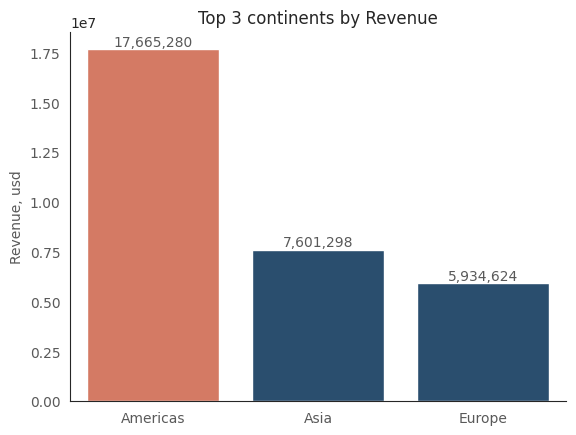

In [ ]:
# Top 3 continents by revenue / Топ-3 континенти за виручкою
ax = sns.barplot(data=top_cont_revenue,
                 x='continent',
                 y='revenue',
                 hue='continent',
                 legend=False,
                 palette=[COLORS['accent']] + [COLORS['main']] * 2)
plt.title('Top 3 continents by Revenue')
plt.xlabel('')
plt.ylabel('Revenue, usd', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

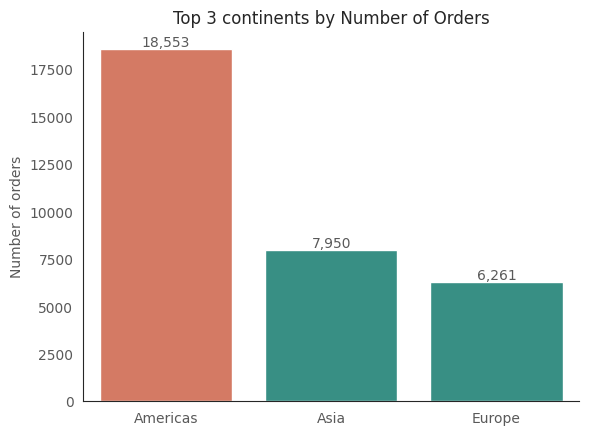

In [ ]:
# Top 3 continents by number of orders / Топ-3 континенти за кількістю замовлень
ax = sns.barplot(data=top_cont_orders,
                 x='continent',
                 y='orders',
                 hue='continent',
                 legend=False,
                 palette=[COLORS['accent']] + [COLORS['second']] * 2)
plt.title('Top 3 continents by Number of Orders')
plt.xlabel('')
plt.ylabel('Number of orders', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

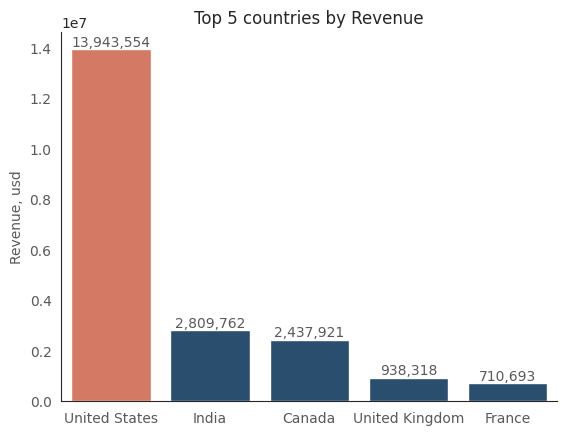

In [ ]:
# Top 5 countries by revenue / Топ-5 країн за виручкою
ax = sns.barplot(data=top_country_revenue,
                 x='country',
                 y='revenue',
                 hue='country',
                 legend=False,
                 palette=[COLORS['accent']] + [COLORS['main']] * 4)
plt.title('Top 5 countries by Revenue')
plt.xlabel('')
plt.ylabel('Revenue, usd', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

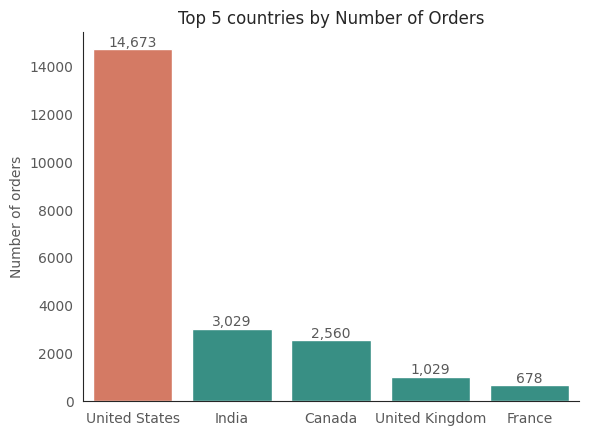

In [ ]:
# Top 5 countries by number of orders / Топ-5 країн за кількістю замовлень
ax = sns.barplot(data=top_country_orders,
                 x='country',
                 y='orders',
                 hue='country',
                 legend=False,
                 palette=[COLORS['accent']] + [COLORS['second']] * 4)
plt.title('Top 5 countries by Number of Orders')
plt.xlabel('')
plt.ylabel('Number of orders', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

In [ ]:
# Average order value = revenue / orders / Середній чек
continent_stats['aov'] = (continent_stats['revenue'] / continent_stats['orders']).round(1)
country_stats['aov'] = (country_stats['revenue'] / country_stats['orders']).round(1)

print(continent_stats.sort_values('aov', ascending=False))
print(country_stats.sort_values('aov', ascending=False).head(5))

              revenue  orders     aov
continent                            
Unknown       74067.4      71  1043.2
Oceania      365230.2     364  1003.4
Africa       331231.0     339   977.1
Asia        7601298.3    7950   956.1
Americas   17665280.0   18553   952.2
Europe      5934624.2    6261   947.9
           revenue  orders     aov
country                           
Palestine  22720.0      13  1747.7
Bulgaria   54652.0      36  1518.1
Albania    14015.0      10  1401.5
Venezuela  18158.0      13  1396.8
Kenya      31590.0      23  1373.5


In [ ]:
# Share of total revenue and orders, % / Частка в загальній виручці та замовленнях, %
continent_stats['revenue_share, %'] = (continent_stats['revenue'] / continent_stats['revenue'].sum() * 100).round(1)
continent_stats['orders_share, %'] = (continent_stats['orders'] / continent_stats['orders'].sum() * 100).round(1)
print(continent_stats.sort_values('revenue', ascending=False))

              revenue  orders     aov  revenue_share, %  orders_share, %
continent                                                               
Americas   17665280.0   18553   952.2              55.3             55.3
Asia        7601298.3    7950   956.1              23.8             23.7
Europe      5934624.2    6261   947.9              18.6             18.7
Oceania      365230.2     364  1003.4               1.1              1.1
Africa       331231.0     339   977.1               1.0              1.0
Unknown       74067.4      71  1043.2               0.2              0.2


4.1 The Americas is the top continent by both revenue (17,665,280 usd, 55.3%) and number of orders (18,553). Asia (7,601,298 usd, 7,950 orders) and Europe (5,934,624 usd, 6,261 orders) follow. The United States is the top country by both revenue (13,943,554 usd) and number of orders (14,673). India, Canada, the United Kingdom and France complete the top 5 in the same order for both metrics

**Additional insights**

Average order value is almost the same across the top continents (Asia 956.1, Americas 952.2, Europe 947.9 usd), so the revenue gap between them comes from the number of orders, not from the price of purchases. The shares of each continent in revenue and in orders are also almost equal (for example, Americas 55.3% in both). The highest average order values by country (Palestine 1,747.7, Bulgaria 1,518.1) are based on only 10-36 orders, so they are unstable and should not be used for conclusions.

------------

4.1 Americas є лідером серед континентів як за виручкою (17 665 280 usd, 55,3%), так і за кількістю замовлень (18 553). Далі йдуть Asia (7 601 298 usd, 7 950 замовлень) та Europe (5 934 624 usd, 6 261 замовлення). United States є лідером серед країн як за виручкою (13 943 554 usd), так і за кількістю замовлень (14 673). India, Canada, United Kingdom та France завершують топ-5 в тому ж порядку за обома показниками.

**Додаткові інсайди**

Середній чек майже однаковий у топ-3 континентів (Asia 956,1, Americas 952,2, Europe 947,9 usd), тому різниця у виручці між ними зумовлена кількістю замовлень, а не вартістю покупок. Частки кожного континенту у виручці та в замовленнях також майже збігаються (наприклад, Americas 55,3% в обох). Найвищі середні чеки за країнами (Palestine 1 747,7, Bulgaria 1 518,1) ґрунтуються лише на 10-36 замовленнях, тому вони нестабільні, і висновки на їх основі робити не варто.

**4.2 Find the top 10 product categories by revenue**

---------

Знайди топ-10 категорій товарів за загальною виручкою

In [ ]:
# Total revenue and number of orders by product category / Виручка та кількість замовлень за категоріями товарів
category_stats = orders.groupby('product_category').agg(revenue=('revenue', 'sum'), orders=('session_id', 'count'))

# Share of total revenue, % / Частка в загальній виручці, %
category_stats['revenue_share, %'] = (category_stats['revenue'] / category_stats['revenue'].sum() * 100).round(1)

# Top 10 categories by revenue / Топ-10 категорій за виручкою
top_cat_revenue = category_stats.sort_values('revenue', ascending=False).head(10)
print(top_cat_revenue)

                                    revenue  orders  revenue_share, %
product_category                                                     
Sofas & armchairs                 8388254.5    4301              26.2
Chairs                            6147748.8    5952              19.2
Beds                              4919725.0    2926              15.4
Bookcases & shelving units        3640818.1    7630              11.4
Cabinets & cupboards              2336499.5    2318               7.3
Outdoor furniture                 2142222.2    2229               6.7
Tables & desks                    1790307.5    2941               5.6
Chests of drawers & drawer units   906562.5    1452               2.8
Bar furniture                      735503.0    1092               2.3
Children's furniture               467697.0    1702               1.5


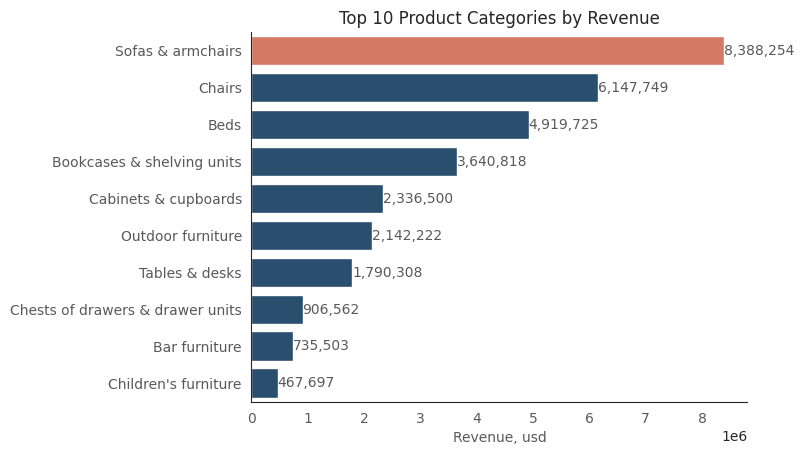

In [ ]:
# Top 10 product categories by revenue / Топ-10 категорій товарів за виручкою
top_cat_revenue = top_cat_revenue.reset_index()

ax = sns.barplot(data=top_cat_revenue,
                 x='revenue',
                 y='product_category',
                 hue='product_category',
                 legend=False,
                 palette=[COLORS['accent']] + [COLORS['main']] * 9)
plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Revenue, usd', fontsize=10, color=NEUTRAL)
plt.ylabel('')
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

In [ ]:
# Share of top 10 categories in total revenue, % / Частка топ-10 категорій у загальній виручці, %
print(top_cat_revenue['revenue_share, %'].sum().round(1))

98.4


4.2 The top 10 product categories by revenue are led by Sofas & armchairs (8,388,254 usd, 26.2%), followed by Chairs (6,147,749 usd, 19.2%), Beds (4,919,725 usd, 15.4%) and Bookcases & shelving units (3,640,818 usd, 11.4%). Together, these four categories generate about 72% of the total revenue. Cabinets & cupboards, Outdoor furniture, Tables & desks, Chests of drawers & drawer units, Bar furniture and Children’s furniture complete the top 10. All 10 categories together give 98.4% of the total revenue.

------------

Топ-10 категорій товарів за виручкою очолюють Sofas & armchairs (8 388 254 usd, 26,2%), Chairs (6 147 749 usd, 19,2%), Beds (4 919 725 usd, 15,4%) та Bookcases & shelving units (3 640 818 usd, 11,4%). Ці чотири категорії разом дають близько 72% загальної виручки. Cabinets & cupboards, Outdoor furniture, Tables & desks, Chests of drawers & drawer units, Bar furniture та Children’s furniture завершують топ-10. Усі 10 категорій разом формують 98,4% загальної виручки.

**4.3 Analysis of sales by device type  (as a percentage of revenue)**

----------

Аналіз продажі у розрізі типів девайсів (у % від виручки)

In [ ]:
# Revenue share by device type, % / Частка виручки за типами пристроїв, %
device_share = (orders.groupby('device')['revenue'].sum() / orders['revenue'].sum() * 100).round(1)
print(device_share.sort_values(ascending=False))

device
Desktop    59.0
Mobile     38.7
Tablet      2.3
Name: revenue, dtype: float64


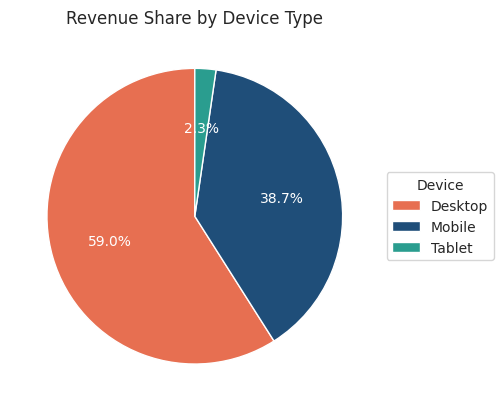

In [ ]:
# Revenue share by device type / Частка виручки за типами пристроїв

device_share = (orders.groupby('device')['revenue'].sum() / orders['revenue'].sum() * 100).round(1).reset_index()
device_share.columns = ['device', 'revenue_share']

plt.pie(device_share['revenue_share'],
        colors=[COLORS['accent'], COLORS['main'], COLORS['second']],
        autopct='%1.1f%%',
        startangle=90,
        textprops={'fontsize': 10, 'color': 'white'})
plt.title('Revenue Share by Device Type')
plt.legend(device_share['device'], title='Device', loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

4.3 Desktop generates the largest share of revenue (59.0%), followed by Mobile (38.7%). Tablet has a very small share (2.3%). Desktop and Mobile together give 97.7% of total revenue.

----------

Desktop приносить найбільшу частку виручки (59,0%), далі йде Mobile (38,7%). Частка Tablet дуже мала (2,3%). Desktop і Mobile разом дають 97,7% загальної виручки.

**4.4 Analysis of sales by traffic source (as a percentage of revenue and orders)**

---------
Аналіз продажів за джерелами трафіку (у % від виручки та замовлень)

In [ ]:
# Orders share by traffic channel, % / Частка замовлень за каналами трафіку, %
channel_orders_share = (orders.groupby('traffic_channel')['session_id'].count() / len(orders) * 100).round(1)
print(channel_orders_share.sort_values(ascending=False))

traffic_channel
Organic Search    35.5
Paid Search       27.0
Direct            23.3
Social Search      8.1
Undefined          6.1
Name: session_id, dtype: float64


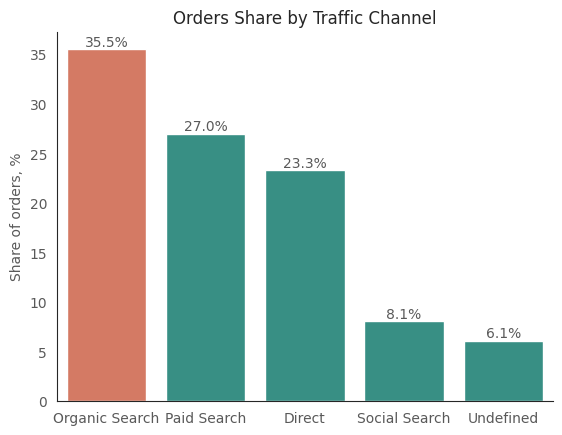

In [ ]:
# Orders share by traffic channel / Частка замовлень за каналами трафіку
channel_orders_share = channel_orders_share.sort_values(ascending=False).reset_index()
channel_orders_share.columns = ['traffic_channel', 'orders_share']

ax = sns.barplot(data=channel_orders_share, x='traffic_channel', y='orders_share', hue='traffic_channel', legend=False,
                 palette=[COLORS['accent']] + [COLORS['second']] * 4)
plt.title('Orders Share by Traffic Channel')
plt.xlabel('')
plt.ylabel('Share of orders, %', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1f}%', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

In [ ]:
# Revenue share by traffic channel, % / Частка виручки за каналами трафіку, %
channel_share = (orders.groupby('traffic_channel')['revenue'].sum() / orders['revenue'].sum() * 100).round(1)
print(channel_share.sort_values(ascending=False))


traffic_channel
Organic Search    35.8
Paid Search       26.6
Direct            23.4
Social Search      7.9
Undefined          6.3
Name: revenue, dtype: float64


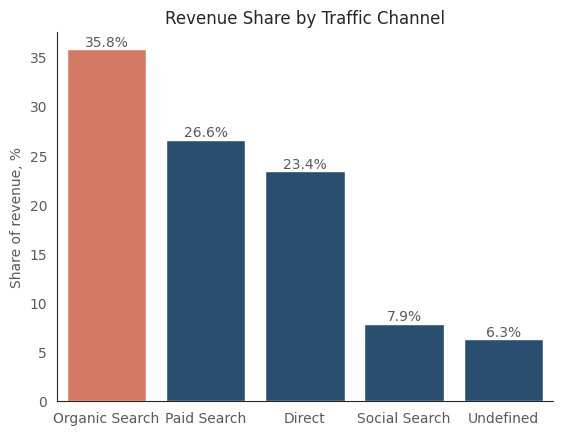

In [ ]:
# Revenue share by traffic channel / Частка виручки за каналами трафіку
channel_share = channel_share.sort_values(ascending=False).reset_index()
channel_share.columns = ['traffic_channel', 'revenue_share']

ax = sns.barplot(data=channel_share, x='traffic_channel', y='revenue_share', hue='traffic_channel', legend=False,
                 palette=[COLORS['accent']] + [COLORS['main']] * 4)
plt.title('Revenue Share by Traffic Channel')
plt.xlabel('')
plt.ylabel('Share of revenue, %', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1f}%', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

4.4 Organic Search generates the largest share of orders (35.5%) and revenue (35.8%). Paid Search and Direct together account for approximately 50% of orders and revenue. The shares of revenue and orders are nearly identical across all channels, indicating a similar contribution to sales.

----------

Organic Search приносить найбільшу частку замовлень (35,5%) і доходу (35,8%). Paid Search і Direct разом забезпечують близько 50% замовлень і доходу. Частки доходу та замовлень майже збігаються в усіх каналах, що свідчить про подібний внесок у продажі.

**4.5 What percentage of registered users have confirmed their email address?
What percentage of registered users have unsubscribed from the newsletter?**

----------

Який відсоток зареєстрованих користувачів підтвердив свою електронну адресу? Який відсоток зареєстрованих користувачів відписався від розсилки?


In [ ]:
# Registered users only (one row per account) / Лише зареєстровані користувачі (один рядок на акаунт)
registered = data[data['account_id'] != 'Guest'].drop_duplicates('account_id')
print('Registered accounts:', len(registered))

Registered accounts: 27945


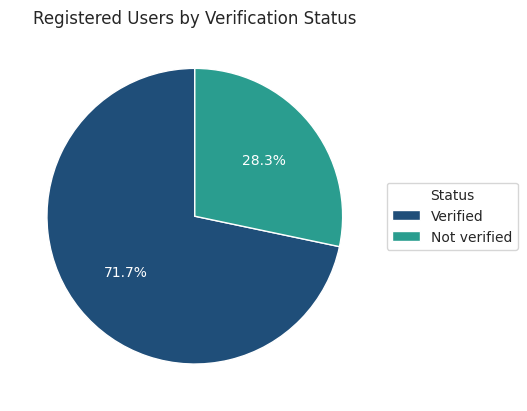

In [ ]:
# Share of verified accounts, % / Частка верифікованих акаунтів, %
verification_share = (registered['verification_status'].value_counts(normalize=True) * 100).round(1).reset_index()
verification_share.columns = ['verification_status', 'share']

plt.pie(verification_share['share'],
        colors=[COLORS['main'], COLORS['second']],
        autopct='%1.1f%%',
        startangle=90,
        textprops={'fontsize': 10, 'color': 'white'})
plt.title('Registered Users by Verification Status')
plt.legend(verification_share['verification_status'], title='Status', loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

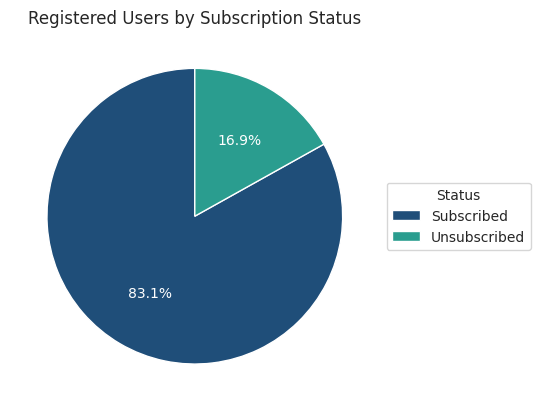

In [ ]:
# Share of unsubscribed accounts, % / Частка акаунтів, що відписалися від розсилки, %
subscription_share = (registered['subscription_status'].value_counts(normalize=True) * 100).round(1).reset_index()
subscription_share.columns = ['subscription_status', 'share']

plt.pie(subscription_share['share'],
        colors=[COLORS['main'], COLORS['second']],
        autopct='%1.1f%%',
        startangle=90,
        textprops={'fontsize': 10, 'color': 'white'})
plt.title('Registered Users by Subscription Status')
plt.legend(subscription_share['subscription_status'], title='Status', loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

4.5 Of 27,945 registered users, 71.7% have verified their email address, and 28.3% have not. 16.9% of registered users have unsubscribed from the mailing list, while 83.1% remain subscribed.

---------

Із 27 945 зареєстрованих користувачів 71,7% підтвердили свою електронну адресу, а 28,3% не підтвердили. Від розсилки відписалися 16,9% зареєстрованих користувачів, а 83,1% залишаються підписаними.

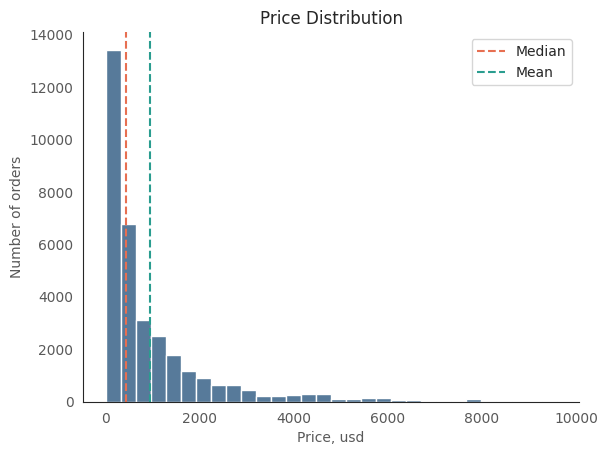

In [ ]:
# 4.6 Distribution of the price by frequency / Розподіл цін за частотою

# Histogram of price (orders only) / Гістограма цін (лише замовлення)
sns.histplot(data=orders, x='price', bins=30, color=COLORS['main'])
plt.title('Price Distribution')
plt.xlabel('Price, usd', fontsize=10, color=NEUTRAL)
plt.ylabel('Number of orders', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
plt.axvline(orders['price'].median(), color=COLORS['accent'], linestyle='--', label='Median')
plt.axvline(orders['price'].mean(), color=COLORS['second'], linestyle='--', label='Mean')
plt.legend()
sns.despine()
plt.show()

In [ ]:
print('Median price:', orders['price'].median(), 'usd')
print('Average price:', f"{orders['price'].mean():.2f}", 'usd')

Median price: 445.0 usd
Average price: 953.30 usd


4.6 Most orders are concentrated in the low price range, and the number of orders drops sharply as the price grows. A small number of expensive orders form a long right tail. Because of this, the mean price (953.30 usd) is more than twice the median (445.00 usd), so the median describes a typical order better than the mean.

------------

Більшість замовлень зосереджена в низькому ціновому діапазоні, а з ростом ціни кількість замовлень різко падає. Невелика кількість дорогих замовлень формує довгий правий хвіст. Через це середня ціна (953,30 usd) більш ніж удвічі перевищує медіану (445,00 usd), тому медіана краще описує типове замовлення, ніж середнє.

## **5.Analysis of sales trends.**

Аналіз динаміки продажів.

**5.1 Total revenue and number of orders for each date; creation of a visualisation of overall sales trends**

-------------
Загальні виторг та кількість замовлень за кожну дату, створення візуалізацію загальної динаміки продажів


In [ ]:
# Make sure session_date is datetime / Перевірка, що session_date у форматі дати
orders = orders.copy()
orders['session_date'] = pd.to_datetime(orders['session_date'])

In [ ]:
# Total revenue and orders per day / Виручка та кількість замовлень за кожен день
daily = orders.groupby('session_date').agg(revenue=('revenue', 'sum'), orders=('session_id', 'count')).reset_index()
print(daily.head(10))

  session_date   revenue  orders
0   2020-11-01  244292.5     281
1   2020-11-02  355506.8     368
2   2020-11-03  498979.6     561
3   2020-11-04  339187.1     370
4   2020-11-05  391276.6     388
5   2020-11-06  322642.2     307
6   2020-11-07  200892.2     215
7   2020-11-08  221162.5     223
8   2020-11-09  302049.5     339
9   2020-11-10  343471.8     374


In [ ]:
# Summary statistics of daily revenue and orders / Підсумкова статистика виручки та замовлень за день
print(daily[['revenue', 'orders']].describe().round(0))

        revenue  orders
count      88.0    88.0
mean   363315.0   381.0
std    100327.0    97.0
min    200892.0   215.0
25%    294145.0   307.0
50%    345354.0   368.0
75%    420637.0   438.0
max    680510.0   689.0


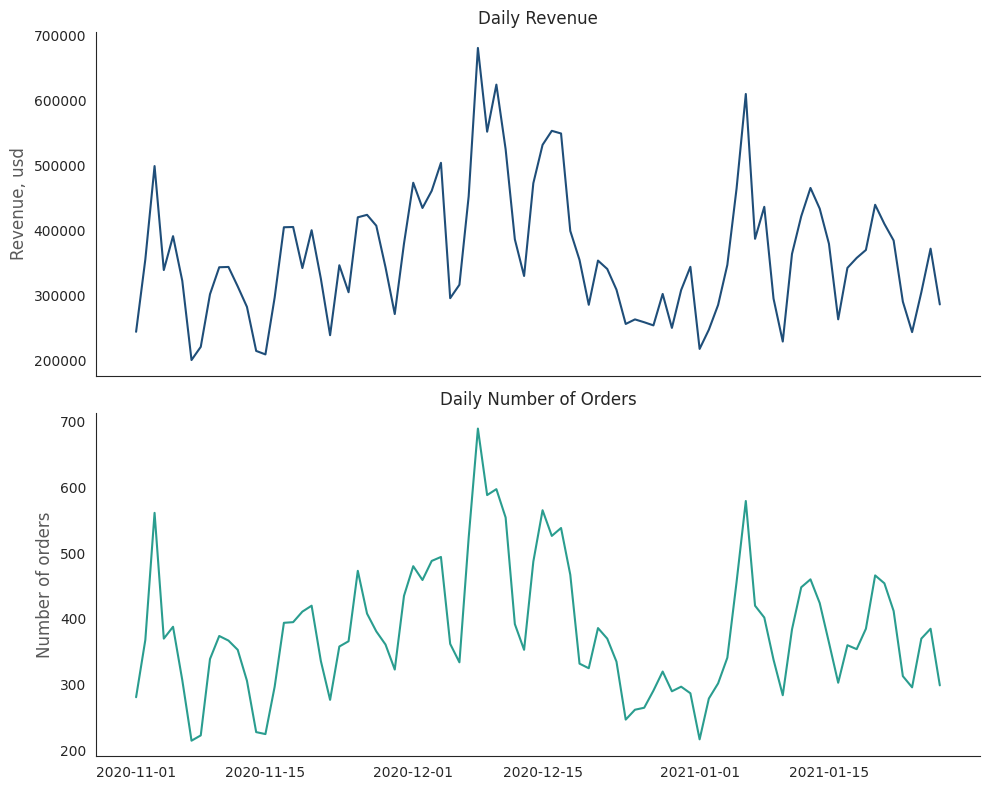

In [ ]:
# Daily revenue and orders / Динаміка виручки та замовлень за днями
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.lineplot(data=daily,
             x='session_date',
             y='revenue',
             color=COLORS['main'],
             ax=ax1)
ax1.set_title('Daily Revenue')
ax1.set_xlabel('')
ax1.set_ylabel('Revenue, usd', fontsize=12, color=NEUTRAL)

sns.lineplot(data=daily,
             x='session_date',
             y='orders',
             color=COLORS['second'],
             ax=ax2)
ax2.set_title('Daily Number of Orders')
ax2.set_xlabel('')
ax2.set_ylabel('Number of orders', fontsize=12, color=NEUTRAL)

sns.despine()
plt.tight_layout()
plt.show()

5.1 Daily revenue and order volume follow almost the same pattern. Across 88 days, average daily revenue was 363 315 usd, with an average of 381 orders. Revenue ranged from 200 892 usd to 680 510 usd, while daily orders varied from 215 to 689. The median daily revenue was 345 354 usd, and the median number of orders was 368. The highest peak occurred in early December 2020, followed by a second peak in early January 2021. Sales dropped in late December and early January before recovering. Overall, sales fluctuate considerably from day to day, with no clear long-term upward or downward trend.

-----------

Щоденна виручка та кількість замовлень змінюються майже однаково. За 88 днів середня щоденна виручка становила 363 315 usd, а середня кількість замовлень — 381. Виручка коливалася від 200 892 usd до 680 510 usd, а кількість замовлень — від 215 до 689 на день. Медіанна виручка становила 345 354 usd, а медіанна кількість замовлень — 368. Найвищий пік спостерігався на початку грудня 2020 року, після чого другий пік припав на початок січня 2021 року. Наприкінці грудня та на початку січня продажі знизилися, але згодом відновилися. Загалом продажі суттєво коливаються щодня, без чіткої довгострокової тенденції до зростання чи спаду.

**5.2 Is there a seasonal pattern to sales?**

---------

Чи спостерігається сезонність продажів?

In [ ]:
# Weekday and month columns / Колонки день тижня та місяць
daily['weekday'] = daily['session_date'].dt.day_name()
daily['month'] = daily['session_date'].dt.strftime('%Y-%m')

# Weekdays in logical order / Дні тижня в логічному порядку
weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Average daily revenue and orders by weekday and month / Середні значення за днем тижня та місяцем
revenue_heatmap = daily.pivot_table(index='weekday', columns='month', values='revenue', aggfunc='mean').reindex(weekdays)
orders_heatmap = daily.pivot_table(index='weekday', columns='month', values='orders', aggfunc='mean').reindex(weekdays)

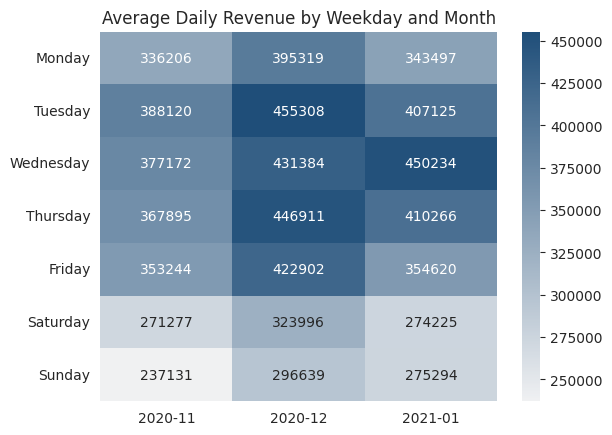

In [ ]:
# Heatmap: average daily revenue / Теплова карта: середня виручка за день
sns.heatmap(revenue_heatmap,
            annot=True,
            fmt='.0f',
            cmap=sns.light_palette(COLORS['main'], as_cmap=True))
plt.title('Average Daily Revenue by Weekday and Month')
plt.xlabel('')
plt.ylabel('')
plt.show()

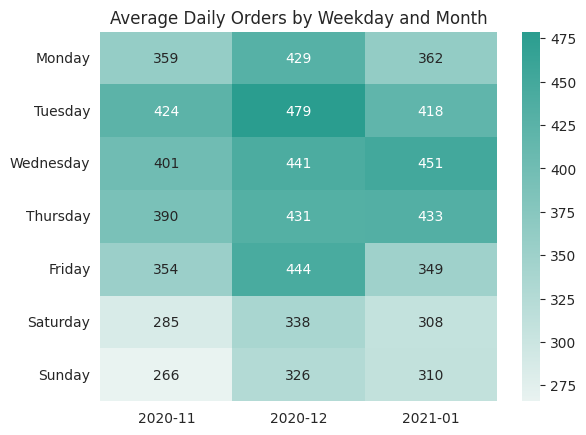

In [ ]:
# Heatmap: average daily orders / Теплова карта: середня кількість замовлень за день
sns.heatmap(orders_heatmap,
            annot=True,
            fmt='.0f',
            cmap=sns.light_palette(COLORS['second'], as_cmap=True))
plt.title('Average Daily Orders by Weekday and Month')
plt.xlabel('')
plt.ylabel('')
plt.show()

5.2 Yes, a weekly seasonality is observed, and it repeats in all three months. Sales are highest on weekdays, mainly Tuesday to Thursday (for example, in December: 455,308 usd and 479 orders on Tuesday), and lowest on weekends, especially Sunday (237,131 usd and 266 orders in November). December has the highest values for every weekday, while the weekday pattern stays the same.

------------

Так, спостерігається тижнева сезонність, яка повторюється в усіх трьох місяцях. Найвищі продажі припадають на будні, переважно з вівторка по четвер (наприклад, у грудні: 455 308 usd і 479 замовлень у вівторок), а найнижчі на вихідні, особливо на неділю (237 131 usd і 266 замовлень у листопаді). У грудні значення вищі за всі дні тижня, але структура за днями тижня залишається тією самою.

**5.3 Analysis of sales trends in America, Asia and Europe. We use different colours to represent the different continents**

----------

Аналіз динаміки продажів в Америці, Азії та Європі. Відображаємо різні континенти різними кольорами

In [ ]:
# Daily revenue and orders by continent / Динаміка за континентами
top3_continents = ['Americas', 'Asia', 'Europe']
continent_daily = (orders[orders['continent'].isin(top3_continents)]
                   .groupby(['session_date', 'continent'])
                   .agg(revenue=('revenue', 'sum'), orders=('session_id', 'count'))
                   .reset_index())

# Colors for continents / Кольори для континентів
continent_colors = {'Americas': COLORS['accent'], 'Asia': COLORS['main'], 'Europe': COLORS['second']}

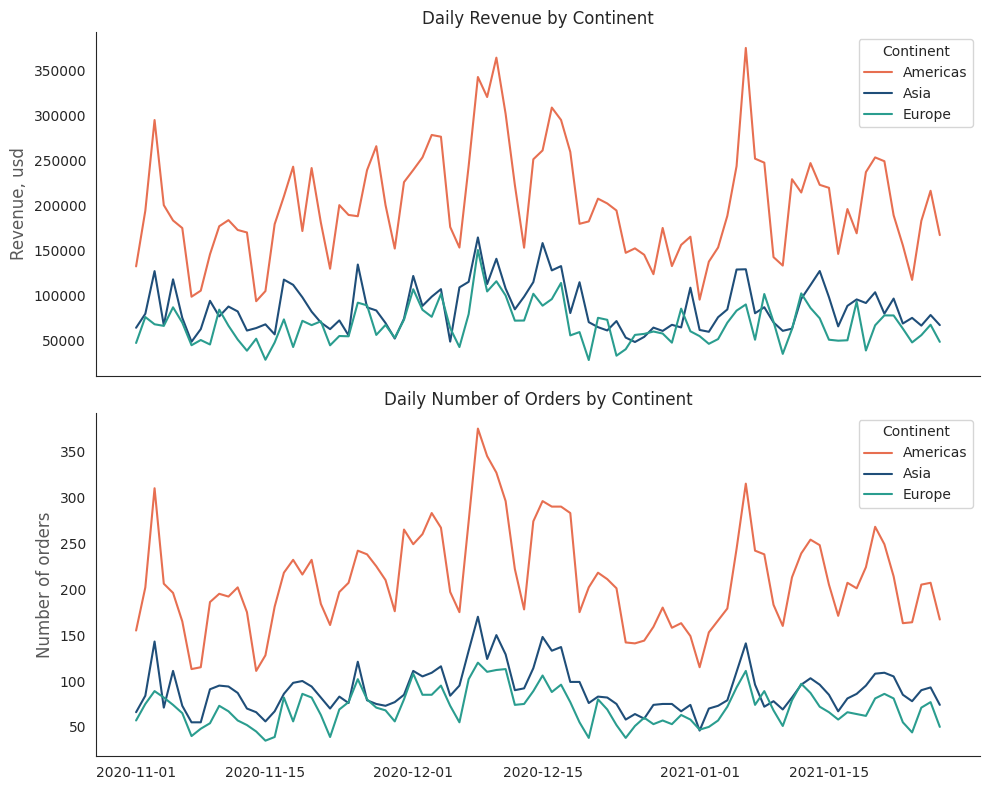

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.lineplot(data=continent_daily,
             x='session_date',
             y='revenue',
             hue='continent',
             palette=continent_colors,
             ax=ax1)
ax1.set_title('Daily Revenue by Continent')
ax1.set_xlabel('')
ax1.set_ylabel('Revenue, usd', fontsize=12, color=NEUTRAL)
ax1.legend(title='Continent')

sns.lineplot(data=continent_daily,
             x='session_date',
             y='orders',
             hue='continent',
             palette=continent_colors,
             ax=ax2)
ax2.set_title('Daily Number of Orders by Continent')
ax2.set_xlabel('')
ax2.set_ylabel('Number of orders', fontsize=12, color=NEUTRAL)
ax2.legend(title='Continent')

sns.despine()
plt.tight_layout()
plt.show()

5.3 The Americas is clearly ahead of Asia and Europe throughout the whole period in both revenue and number of orders, while Asia and Europe are close to each other. All three continents follow the same pattern, with peaks in early December and early January. No clear long-term trend is visible, only short-term fluctuations.

--------------------

Americas протягом усього періоду помітно випереджає Asia та Europe як за виручкою, так і за кількістю замовлень, тоді як Asia та Europe близькі між собою. Усі три континенти мають схожу динаміку з піками на початку грудня та на початку січня. Чіткого довгострокового тренду немає, лише короткострокові коливання.

**5.4 Sales trends by device type**

-----------

Динаміка продажів у розрізі типів девайсів

In [ ]:
# Daily revenue and orders by device / Динаміка за типами пристроїв
device_daily = (orders.groupby(['session_date', 'device'])
                .agg(revenue=('revenue', 'sum'), orders=('session_id', 'count'))
                .reset_index())

# Colors for devices (same as in the pie chart) / Кольори для пристроїв (як на pie chart)
device_colors = {'Desktop': COLORS['accent'], 'Mobile': COLORS['main'], 'Tablet': COLORS['second']}

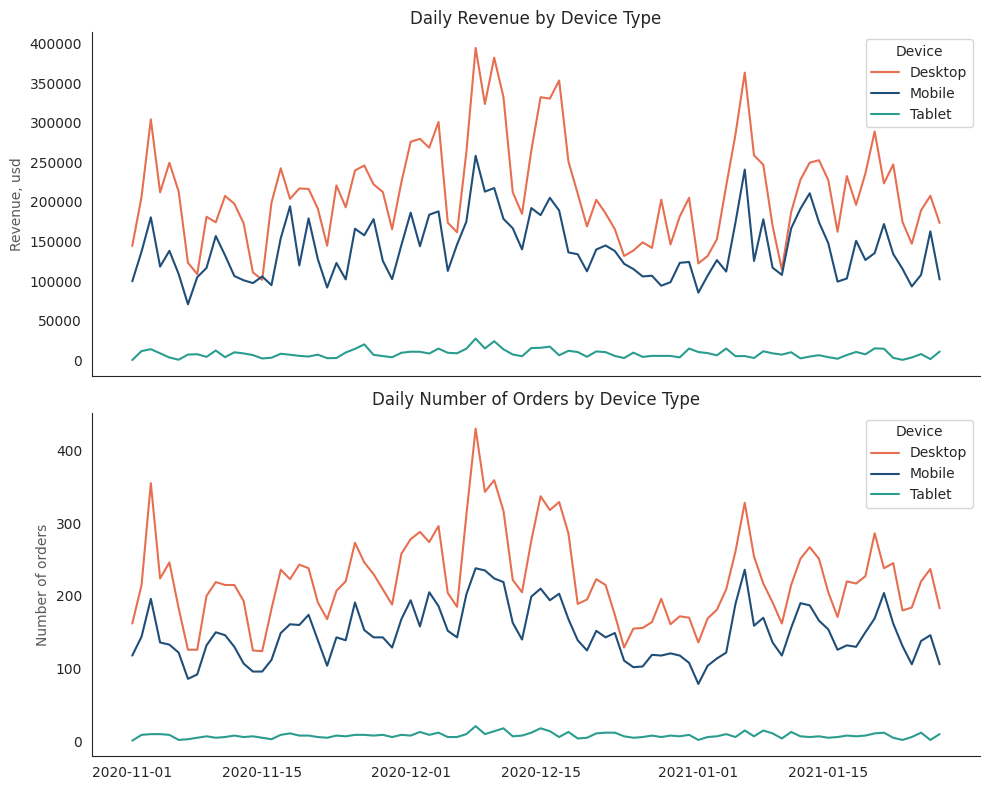

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.lineplot(data=device_daily, x='session_date', y='revenue', hue='device', palette=device_colors, ax=ax1)
ax1.set_title('Daily Revenue by Device Type')
ax1.set_xlabel('')
ax1.set_ylabel('Revenue, usd', fontsize=10, color=NEUTRAL)
ax1.legend(title='Device')

sns.lineplot(data=device_daily, x='session_date', y='orders', hue='device', palette=device_colors, ax=ax2)
ax2.set_title('Daily Number of Orders by Device Type')
ax2.set_xlabel('')
ax2.set_ylabel('Number of orders', fontsize=10, color=NEUTRAL)
ax2.legend(title='Device')

sns.despine()
plt.tight_layout()
plt.show()

5.4 Desktop generates the highest revenue and number of orders throughout the whole period, Mobile is consistently lower, and Tablet is close to zero. All devices follow the same pattern, with peaks in early December and early January. No clear long-term trend is visible, only short-term fluctuations.

-----------------

Desktop протягом усього періоду дає найвищу виручку та кількість замовлень, Mobile стабільно нижчий, а Tablet близький до нуля. Усі девайси мають схожу динаміку з піками на початку грудня та на початку січня. Чіткого довгострокового тренду немає, лише короткострокові коливання.

## **6. Pivot tables**

------
Зведені таблиці.

**6.1 Сreating a pivot table showing total revenue, average price, total orders by product category (top 10 categories) in different countries (top 5 countries)**

--------
Створення зведеної таблиці, яка показує загальний виторг, середню ціну, загальну кількість замовлень за категоріями товарів (топ-10 категорій) у різних країнах (топ-5 країн)

In [ ]:
# Top 5 countries by revenue / Топ-5 країн за виручкою
top_5_countries_revenue = (
    orders.groupby('country')['revenue']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

# Top 10 product categories by revenue / Топ-10 категорій товарів за виручкою
top_10_categories_revenue = (
    orders[orders['country'].isin(top_5_countries_revenue)]
    .groupby('product_category')['revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

# Filter data by selected countries and categories / Фільтруємо дані за обраними країнами та категоріями
filtered_orders = orders[
    orders['country'].isin(top_5_countries_revenue) &
    orders['product_category'].isin(top_10_categories_revenue)
]

# Create a pivot table / Створюємо зведену таблицю
pivot_table = pd.pivot_table(
    filtered_orders,
    values='revenue',
    index='product_category',
    columns='country',
    aggfunc='sum',
    fill_value=0
)

# Sort countries by total revenue / Сортуємо країни за загальною виручкою
pivot_table = pivot_table[top_5_countries_revenue]

# Sort categories by total revenue / Сортуємо категорії за загальною виручкою
pivot_table = pivot_table.loc[
    pivot_table.sum(axis=1).sort_values(ascending=False).index
]

# Display the pivot table / Виводимо зведену таблицю
print(pivot_table)

country                           United States     India    Canada  \
product_category                                                      
Sofas & armchairs                     3707144.5  788430.0  692427.5   
Chairs                                2619773.8  544309.2  417740.8   
Beds                                  2213058.0  358319.5  354772.0   
Bookcases & shelving units            1567606.9  364507.4  278981.9   
Cabinets & cupboards                   994545.5  191888.0  181802.0   
Outdoor furniture                      929245.2  162289.4  185322.8   
Tables & desks                         777865.0  186157.5  132678.0   
Chests of drawers & drawer units       382388.0   73111.0   71952.0   
Bar furniture                          330805.0   57657.0   51724.0   
Children's furniture                   207575.0   39177.0   30264.0   

country                           United Kingdom    France  
product_category                                            
Sofas & armchairs        

In [ ]:
# Create a pivot table: average price per order by category and country / Створюємо зведену таблицю: середня ціна на замовлення за категоріями та країнами
pivot_table = pd.pivot_table(
    filtered_orders,
    values='price',
    index='product_category',
    columns='country',
    aggfunc='mean',
    fill_value=0
)

# Keep only top 5 countries / Залишаємо лише топ-5 країн
pivot_table = pivot_table[top_5_countries_revenue]

# Sort categories by sum of average revenue across countries / Сортуємо категорії за сумою середньої ціни по країнах
pivot_table = pivot_table.loc[
    pivot_table.sum(axis=1).sort_values(ascending=False).index
]

# Display the pivot table with 2 decimal places / Виводимо зведену таблицю з двома знаками після коми
print(pivot_table.round(2))

country                           United States    India   Canada  \
product_category                                                    
Sofas & armchairs                       1948.05  1990.98  2091.93   
Beds                                    1704.98  1518.30  1627.39   
Chairs                                  1016.99  1009.85   928.31   
Cabinets & cupboards                     999.54   954.67   988.05   
Outdoor furniture                        944.35   886.83  1047.02   
Bar furniture                            679.27   600.59   623.18   
Tables & desks                           623.29   648.63   605.84   
Chests of drawers & drawer units         620.76   566.75   636.74   
Bookcases & shelving units               464.61   496.60   472.05   
Children's furniture                     276.03   275.89   260.90   

country                           United Kingdom   France  
product_category                                           
Sofas & armchairs                        1713.96  2

In [ ]:
# Top 5 countries by number of orders / Топ-5 країн за кількістю замовлень
top_5_countries_orders = (
    orders.groupby('country')['session_id']
    .count()
    .sort_values(ascending=False)
    .head(5)
    .index
)

# Top 10 product categories by number of orders in top 5 countries / Топ-10 категорій товарів за кількістю замовлень у топ-5 країнах
top_10_categories_orders = (
    orders[orders['country'].isin(top_5_countries_orders)]
    .groupby('product_category')['session_id']
    .count()
    .sort_values(ascending=False)
    .head(10)
    .index
)

# Filter data by selected countries and categories / Фільтруємо дані за обраними країнами та категоріями
filtered_orders = orders[
    orders['country'].isin(top_5_countries_orders) &
    orders['product_category'].isin(top_10_categories_orders)
]

# Create a pivot table: number of orders / Створюємо зведену таблицю: кількість замовлень
pivot_table_orders = pd.pivot_table(
    filtered_orders,
    values='session_id',
    index='product_category',
    columns='country',
    aggfunc='count',
    fill_value=0
)

# Sort countries by total number of orders / Сортуємо країни за загальною кількістю замовлень
pivot_table_orders = pivot_table_orders[top_5_countries_orders]

# Sort categories by total number of orders / Сортуємо категорії за загальною кількістю замовлень
pivot_table_orders = pivot_table_orders.loc[
    pivot_table_orders.sum(axis=1).sort_values(ascending=False).index
]

# Display the pivot table / Виводимо зведену таблицю
print(pivot_table_orders)

country                           United States  India  Canada  \
product_category                                                 
Bookcases & shelving units                 3374    734     591   
Chairs                                     2576    539     450   
Sofas & armchairs                          1903    396     331   
Beds                                       1298    236     218   
Tables & desks                             1248    287     219   
Cabinets & cupboards                        995    201     184   
Outdoor furniture                           984    183     177   
Children's furniture                        752    142     116   
Chests of drawers & drawer units            616    129     113   
Bar furniture                               487     96      83   

country                           United Kingdom  France  
product_category                                          
Bookcases & shelving units                   232     144  
Chairs                        

In [ ]:
# Find the country with the highest revenue / Знаходимо країну з найбільшою виручкою (United States)
top_country = orders.groupby('country')['revenue'].sum().idxmax()

# Calculate revenue and number of orders by product category in the selected country / Розраховуємо виручку та кількість замовлень за категоріями товарів у вибраній країні
country_category_stats = (
    orders[orders['country'] == top_country]
    .groupby('product_category')
    .agg(
        revenue=('revenue', 'sum'),
        orders=('session_id', 'count')
    )
    .sort_values('revenue', ascending=False)
)

# Display the selected country / Виводимо назву вибраної країни
print(f'Country: {top_country}')

# Display category statistics / Виводимо статистику за категоріями
print(country_category_stats)

Country: United States
                                        revenue  orders
product_category                                       
Sofas & armchairs                     3707144.5    1903
Chairs                                2619773.8    2576
Beds                                  2213058.0    1298
Bookcases & shelving units            1567606.9    3374
Cabinets & cupboards                   994545.5     995
Outdoor furniture                      929245.2     984
Tables & desks                         777865.0    1248
Chests of drawers & drawer units       382388.0     616
Bar furniture                          330805.0     487
Children's furniture                   207575.0     752
Nursery furniture                       65998.0     183
Café furniture                          59000.0     161
Sideboards, buffets & console tables    58110.0      57
Room dividers                           30439.0      39


6.1 Sofas & armchairs generate the highest revenue in all five countries, followed by Chairs and Beds, and the United States leads in every category. This is driven by a high average price (about 1,700-2,100 usd), not by order volume: Bookcases & shelving units have the most orders but one of the lowest average prices (about 465-513 usd). Children’s furniture has the lowest revenue, with the lowest average price and few orders.

--------------

Sofas & armchairs забезпечують найбільшу виручку в усіх п'яти країнах, за ними йдуть Chairs та Beds, а США лідирують у кожній категорії. Це зумовлено високою середньою ціною (приблизно 1 700-2 100 usd), а не кількістю замовлень: Bookcases & shelving units мають найбільше замовлень, але одну з найнижчих середніх цін (приблизно 465-513 usd). Children’s furniture має найнижчу виручку через найнижчу середню ціну та малу кількість замовлень.


**6.2 Сreating a pivot table showing the number of sessions broken down by traffic channels and device types**

-----------------
Створення зведеної таблиці, яка показує кількість сесій у розрізі каналів трафіку та типів девайсів

In [ ]:
# Exclude unknown channel values / Виключаємо невідомі значення каналу
# (device has no unknown values, so only traffic_channel needs filtering)
known = data[data['traffic_channel'] != 'Undefined']

# Pivot table: number of sessions by traffic channel and device / Зведена таблиця: кількість сесій за каналами трафіку та пристроями
sessions_pivot = known.pivot_table(index='traffic_channel',
                                   columns='device',
                                   values='session_id',
                                   aggfunc='count')
# Display the pivot table / Виводимо зведену таблицю
print(sessions_pivot)

device           Desktop  Mobile  Tablet
traffic_channel                         
Direct             47825   31745    1812
Organic Search     72622   49014    2789
Paid Search        55167   37034    2140
Social Search      16288   10988     638


6.2 Organic Search is the largest source of sessions on every device type (72,622 on Desktop, 49,014 on Mobile), followed by Paid Search, Direct and Social Search. The ranking of channels is the same for Desktop, Mobile and Tablet, and Desktop dominates in every channel, with Mobile in second place and Tablet far behind.

--------------

Organic Search є найбільшим джерелом сесій на кожному типі пристроїв (72 622 на Desktop, 49 014 на Mobile), далі йдуть Paid Search, Direct та Social Search. Рейтинг каналів однаковий для Desktop, Mobile і Tablet, а Desktop домінує в кожному каналі, Mobile на другому місці, Tablet значно поступається.

## **7. Statistical analysis of correlations**

------------
Статистичний аналіз взаємозв’язків.

7.1
We calculate the number of sessions and total sales for each date. We create a visualisation to see the relationship between these metrics. Do these metrics correlate? We calculate the corresponding correlation coefficient and analyse its statistical significance.

------------

Знаходимо кількість сесій та загальні продажі за кожну дату. Створюємо візуалізацію, щоб побачити взаємозв’язок між цими метриками. Чи корелюють ці показники? Знаходимо відповідний коефіцієнт кореляції та аналізуємо його статистичну значущість.

In [ ]:
# Days with no tracked revenue (Jan 28-31) are excluded, same as in section 5
# Дні без виручки (28-31 січня) виключаємо, як і в розділі 5
sessions_revenue = data.groupby('session_date').agg(sessions=('session_id', 'count'),
                                                    revenue=('revenue', 'sum')).reset_index()
print('Number of days before filter:', len(sessions_revenue))

sessions_revenue = sessions_revenue[sessions_revenue['revenue'] > 0]
print('Number of days after filter:', len(sessions_revenue))  # очікується 88
print(sessions_revenue.head())
print(sessions_revenue.tail())

Number of days before filter: 92
Number of days after filter: 88
  session_date  sessions   revenue
0   2020-11-01      2576  244292.5
1   2020-11-02      3599  355506.8
2   2020-11-03      5173  498979.6
3   2020-11-04      4184  339187.1
4   2020-11-05      3743  391276.6
   session_date  sessions   revenue
83   2021-01-23      3067  290605.5
84   2021-01-24      2893  243818.4
85   2021-01-25      3760  305089.3
86   2021-01-26      3970  372057.3
87   2021-01-27      4435  286340.7


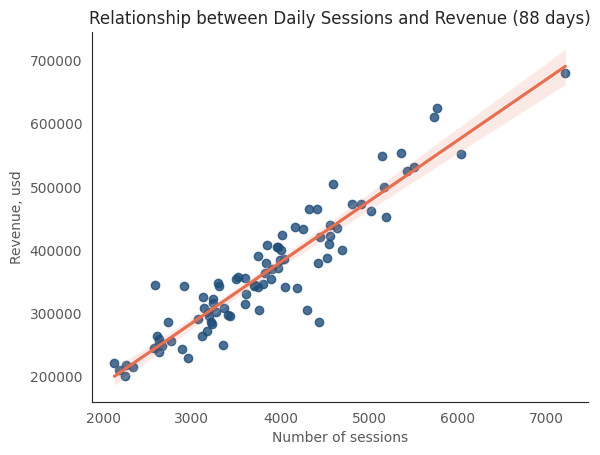

In [ ]:
# Scatter plot: sessions vs revenue (without zero days) / Діаграма розсіювання без нульових днів
sns.regplot(data=sessions_revenue,
            x='sessions',
            y='revenue',
            scatter_kws={'color': COLORS['main']},
            line_kws={'color': COLORS['accent']})
plt.title('Relationship between Daily Sessions and Revenue (88 days)')
plt.xlabel('Number of sessions', fontsize=10, color=NEUTRAL)
plt.ylabel('Revenue, usd', fontsize=10, color=NEUTRAL)
plt.xticks(fontsize=10, color=NEUTRAL)
plt.yticks(fontsize=10, color=NEUTRAL)
sns.despine()
plt.show()

In [ ]:
# Pearson correlation (linear relationship) / Кореляція Пірсона
pearson_r, pearson_p = stats.pearsonr(sessions_revenue['sessions'], sessions_revenue['revenue'])
print('Pearson r:', round(pearson_r, 3))
print('Pearson p-value:', pearson_p)

# Spearman correlation (monotonic relationship) / Кореляція Спірмена
spearman_r, spearman_p = stats.spearmanr(sessions_revenue['sessions'], sessions_revenue['revenue'])
print('Spearman rho:', round(spearman_r, 3))
print('Spearman p-value:', spearman_p)

Pearson r: 0.931
Pearson p-value: 1.7394621412998283e-39
Spearman rho: 0.904
Spearman p-value: 1.5381769633064087e-33


7.1 Yes, daily sessions and daily revenue are strongly positively correlated: as sessions grow, revenue grows too. Pearson r = 0.93 (linear relationship) and Spearman rho = [X] (monotonic relationship). Both p-values are far below 0.05 ([p1] and [p2]), so the correlation is statistically significant (n = 88 days). The period 28-31 January 2021 is excluded: these days have sessions but zero revenue, which most likely means missing revenue data rather than real user behavior, and the same days are excluded in section 5. With all 92 days, these four points lay far below the trend line and lowered Pearson r to 0.791, while Spearman was less affected (0.865) because it is robust to outliers. Correlation does not prove causation: sessions with orders are also part of the total number of sessions.

----------

Так, кількість сесій і виручка за день мають сильний додатний зв'язок: із зростанням кількості сесій зростає й виручка. Коефіцієнт Пірсона r = 0,93 (лінійний зв'язок), Спірмена rho = [X] (монотонний зв'язок). Обидва p-value значно менші за 0,05 ([p1] та [p2]), тому кореляція статистично значуща (n = 88 днів). Період 28-31 січня 2021 виключено: у ці дні є сесії, але виручка дорівнює нулю, що найімовірніше означає відсутність даних про виручку, а не реальну поведінку користувачів. Ці самі дні виключені в розділі 5. Якщо брати всі 92 дні, ці чотири точки лежать значно нижче лінії тренду й знижують Пірсона до 0,791, а Спірмен змінюється менше (0,865), бо він стійкий до викидів. Кореляція не доводить причинно-наслідкового зв'язку: сесії із замовленнями також входять до загальної кількості сесій.

**7.2 Is there a correlation between sales on different continents? Take the top three continents. Analyse the statistical significance of the correlations**

-------------------

Чи корелюють між собою продажі на різних континентах? Візьми топ-3 континенти. Проаналізуй статистичну значущість взаємозв’язків.

In [ ]:
# Daily revenue by continent / Щоденна виручка за континентами
continent_wide = (orders[orders['continent'].isin(['Americas', 'Asia', 'Europe'])]
                  .pivot_table(index='session_date', columns='continent', values='revenue', aggfunc='sum')
                  .fillna(0))

# Spearman correlation matrix / Матриця кореляцій Спірмена
corr_cont = continent_wide.corr(method='spearman').round(3)
print(corr_cont)

continent  Americas   Asia  Europe
continent                         
Americas      1.000  0.669   0.626
Asia          0.669  1.000   0.608
Europe        0.626  0.608   1.000


In [ ]:
# P-values for each pair of continents / P-values для кожної пари континентів
print('Americas - Asia:', stats.spearmanr(continent_wide['Americas'], continent_wide['Asia'])[1])
print('Americas - Europe:', stats.spearmanr(continent_wide['Americas'], continent_wide['Europe'])[1])
print('Asia - Europe:', stats.spearmanr(continent_wide['Asia'], continent_wide['Europe'])[1])

Americas - Asia: 1.1001059722381636e-12
Americas - Europe: 7.009052955139405e-11
Asia - Europe: 3.2731384105062476e-10


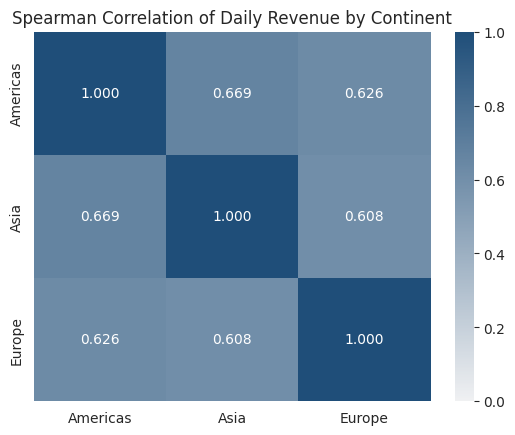

In [ ]:
# Heatmap: correlation of daily revenue by continent / Теплова карта: кореляція виручки за континентами
sns.heatmap(corr_cont,
            annot=True,
            fmt='.3f',
            vmin=0,
            vmax=1,
            cmap=sns.light_palette(COLORS['main'], as_cmap=True))
plt.title('Spearman Correlation of Daily Revenue by Continent')
plt.xlabel('')
plt.ylabel('')
plt.show()

7.2 Daily revenue is moderately to strongly positively correlated across all pairs (Spearman 0.61-0.67). All p-values are far below 0.05, so the relationships are statistically significant.

------

Щоденна виручка має помірний або сильний додатний зв'язок у всіх парах (Спірмен 0,61-0,67). Усі p-value значно менші за 0,05, тому зв'язки статистично значущі.

**7.3 Do sales across different traffic channels correlate with one another? We analyse the statistical significance of these correlations.**

---------

Чи корелюють між собою продажі за різними каналами трафіку? Аналізуємо статистичну значущість взаємозв’язків.

In [ ]:
# Daily revenue by traffic channel / Щоденна виручка за каналами трафіку
channel_wide = (orders.pivot_table(index='session_date', columns='traffic_channel', values='revenue', aggfunc='sum')
                .fillna(0))

# Spearman correlation matrix / Матриця кореляцій Спірмена
corr_ch = channel_wide.corr(method='spearman').round(3)
print(corr_ch)

traffic_channel  Direct  Organic Search  Paid Search  Social Search  Undefined
traffic_channel                                                               
Direct            1.000           0.748        0.691          0.394      0.494
Organic Search    0.748           1.000        0.764          0.385      0.457
Paid Search       0.691           0.764        1.000          0.420      0.493
Social Search     0.394           0.385        0.420          1.000      0.386
Undefined         0.494           0.457        0.493          0.386      1.000


In [ ]:
# P-values for each pair of channels / P-values для кожної пари каналів
print('Organic Search - Paid Search:', stats.spearmanr(channel_wide['Organic Search'], channel_wide['Paid Search'])[1])
print('Organic Search - Direct:', stats.spearmanr(channel_wide['Organic Search'], channel_wide['Direct'])[1])
print('Organic Search - Social Search:', stats.spearmanr(channel_wide['Organic Search'], channel_wide['Social Search'])[1])
print('Organic Search - Undefined:', stats.spearmanr(channel_wide['Organic Search'], channel_wide['Undefined'])[1])
print('Paid Search - Direct:', stats.spearmanr(channel_wide['Paid Search'], channel_wide['Direct'])[1])
print('Paid Search - Social Search:', stats.spearmanr(channel_wide['Paid Search'], channel_wide['Social Search'])[1])
print('Paid Search - Undefined:', stats.spearmanr(channel_wide['Paid Search'], channel_wide['Undefined'])[1])
print('Direct - Social Search:', stats.spearmanr(channel_wide['Direct'], channel_wide['Social Search'])[1])
print('Direct - Undefined:', stats.spearmanr(channel_wide['Direct'], channel_wide['Undefined'])[1])
print('Social Search - Undefined:', stats.spearmanr(channel_wide['Social Search'], channel_wide['Undefined'])[1])

Organic Search - Paid Search: 4.8634931780185696e-18
Organic Search - Direct: 5.362547239818307e-17
Organic Search - Social Search: 0.00021439393779222672
Organic Search - Undefined: 7.651394403515162e-06
Paid Search - Direct: 9.505458925584083e-14
Paid Search - Social Search: 4.543779404049375e-05
Paid Search - Undefined: 1.0467901916051605e-06
Direct - Social Search: 0.00014782706768003086
Direct - Undefined: 1.0172911287944853e-06
Social Search - Undefined: 0.0002046648697413209


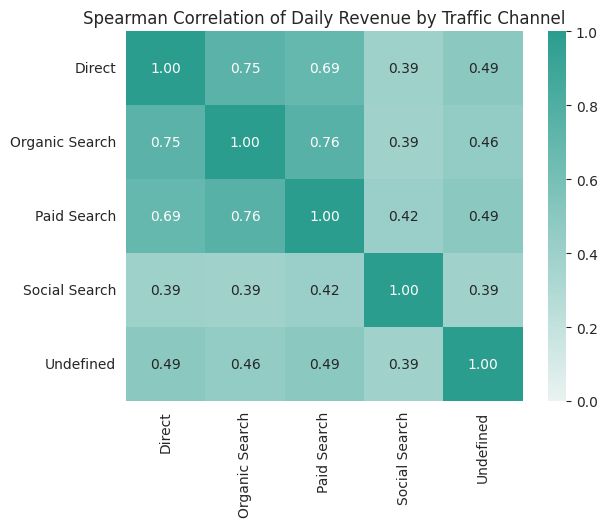

In [ ]:
# Heatmap: correlation of daily revenue by traffic channel / Теплова карта: кореляція виручки за каналами
sns.heatmap(corr_ch,
            annot=True,
            fmt='.2f',
            vmin=0,
            vmax=1,
            cmap=sns.light_palette(COLORS['second'], as_cmap=True))
plt.title('Spearman Correlation of Daily Revenue by Traffic Channel')
plt.xlabel('')
plt.ylabel('')
plt.show()

All channel pairs correlate positively and significantly (p < 0.05). The strongest links are among Organic Search, Paid Search and Direct (0.69-0.76), while Social Search is weaker (about 0.39-0.42).

-------

Усі пари каналів корелюють додатно й значущо (p < 0,05). Найсильніший зв'язок між Organic Search, Paid Search і Direct (0,69-0,76), а Social Search має слабший (приблизно 0,39-0,42).

**7.4  Is there a correlation between sales in the top five product categories? Analyse the statistical significance of these correlations.**

--------

Чи корелюють між собою продажі за топ-5 категоріями товарів? Проаналізуй статистичну значущість взаємозв’язків.

In [ ]:
# Top 5 categories by revenue / Топ-5 категорій за виручкою
top5_cat = orders.groupby('product_category')['revenue'].sum().nlargest(5).index

# Daily revenue by category / Щоденна виручка за категоріями
category_wide = (orders[orders['product_category'].isin(top5_cat)]
                 .pivot_table(index='session_date', columns='product_category', values='revenue', aggfunc='sum')
                 .fillna(0))

# Spearman correlation matrix / Матриця кореляцій Спірмена
corr_cat = category_wide.corr(method='spearman').round(3)
print(corr_cat)
print(len(category_wide))

product_category             Beds  Bookcases & shelving units  \
product_category                                                
Beds                        1.000                       0.543   
Bookcases & shelving units  0.543                       1.000   
Cabinets & cupboards        0.440                       0.529   
Chairs                      0.535                       0.637   
Sofas & armchairs           0.522                       0.626   

product_category            Cabinets & cupboards  Chairs  Sofas & armchairs  
product_category                                                             
Beds                                       0.440   0.535              0.522  
Bookcases & shelving units                 0.529   0.637              0.626  
Cabinets & cupboards                       1.000   0.527              0.631  
Chairs                                     0.527   1.000              0.583  
Sofas & armchairs                          0.631   0.583              1.000 

In [ ]:
# P-values for each pair of categories / P-values для кожної пари категорій
for i in range(len(category_wide.columns)):
    for j in range(i + 1, len(category_wide.columns)):
        a = category_wide.columns[i]
        b = category_wide.columns[j]
        print(a, '-', b, ':', stats.spearmanr(category_wide[a], category_wide[b])[1])

Beds - Bookcases & shelving units : 4.690831718453576e-08
Beds - Cabinets & cupboards : 1.7587830397743514e-05
Beds - Chairs : 7.913415552119658e-08
Beds - Sofas & armchairs : 1.864367723360297e-07
Bookcases & shelving units - Cabinets & cupboards : 1.1906129581027331e-07
Bookcases & shelving units - Chairs : 2.5854375788053062e-11
Bookcases & shelving units - Sofas & armchairs : 7.188990897333014e-11
Cabinets & cupboards - Chairs : 1.3449152556100263e-07
Cabinets & cupboards - Sofas & armchairs : 4.322908272307604e-11
Chairs - Sofas & armchairs : 2.4628200563808208e-09


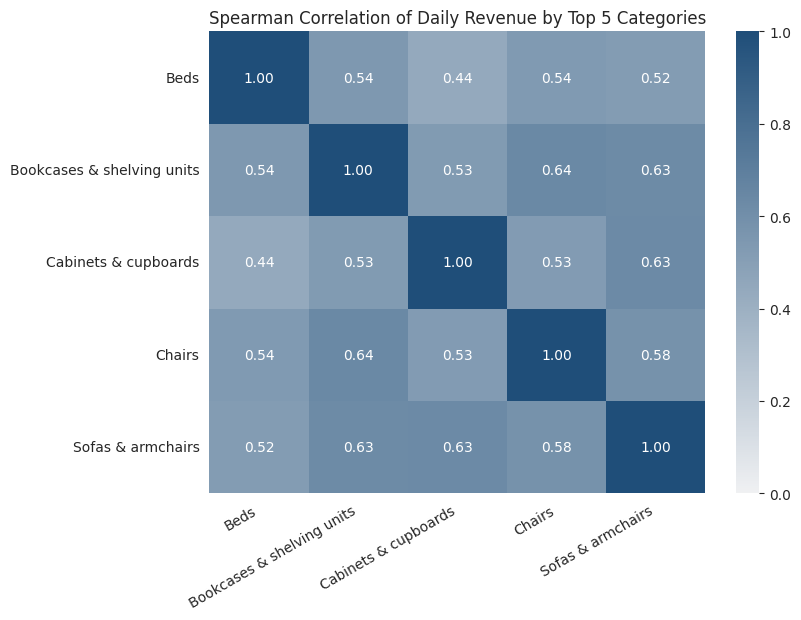

In [ ]:
# Heatmap: correlation of daily revenue by top 5 categories / Теплова карта: кореляція виручки за топ-5 категоріями
plt.figure(figsize=(8, 6))
sns.heatmap(corr_cat,
            annot=True,
            fmt='.2f',
            vmin=0,
            vmax=1,
            cmap=sns.light_palette(COLORS['main'], as_cmap=True))
plt.title('Spearman Correlation of Daily Revenue by Top 5 Categories')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=30, ha='right')
plt.show()

7.4 All categories show a moderate positive correlation (0.44-0.64) with each other. All 10 pairs are statistically significant: p-values range from 2.6e-11 to 1.8e-05, far below 0.05 (n = 88 days).

----------

Усі категорії мають помірний додатний зв'язок між собою (0,44-0,64). Усі 10 пар статистично значущі: p-values від 2,6e-11 до 1,8e-05, що значно менше за 0,05 (n = 88 днів).

**7.5 Correlation between conversions and the number of sessions by day**

----------

Кореляція між конверсією та кількістю сесій за днями

In [ ]:
# Create a flag: 1 if the session has an order, 0 if not / Позначка: 1 якщо є замовлення, 0 якщо немає
data['has_order'] = 0
data.loc[data['revenue'] > 0, 'has_order'] = 1

# Daily sessions, orders and conversion / Сесії, замовлення та конверсія за днями
daily_conv = data.groupby('session_date').agg(sessions=('session_id', 'count'),
                                              orders=('has_order', 'sum')).reset_index()
daily_conv['conversion, %'] = (daily_conv['orders'] / daily_conv['sessions'] * 100).round(2)

# Exclude last days with zero revenue / Виключаємо останні дні з нульовою виручкою
daily_conv = daily_conv[daily_conv['orders'] > 0]

r, p = stats.spearmanr(daily_conv['sessions'], daily_conv['conversion, %'])
print('Spearman rho (sessions vs conversion):', round(r, 3), '| p-value:', p)

Spearman rho (sessions vs conversion): -0.131 | p-value: 0.22434606296624623


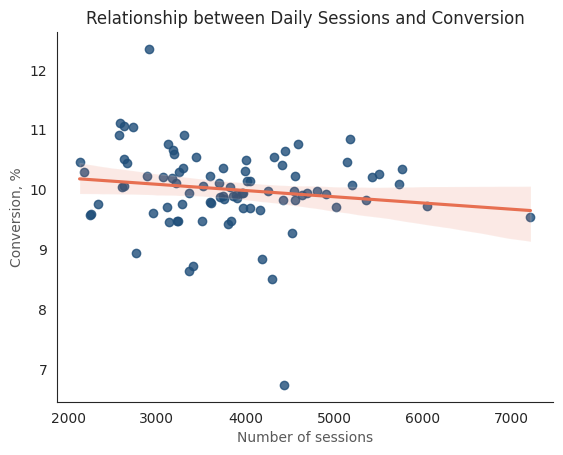

In [ ]:
# Scatter plot: sessions vs conversion / Діаграма розсіювання: сесії та конверсія
sns.regplot(data=daily_conv,
            x='sessions',
            y='conversion, %',
            scatter_kws={'color': COLORS['main']},
            line_kws={'color': COLORS['accent']})
plt.title('Relationship between Daily Sessions and Conversion')
plt.xlabel('Number of sessions', fontsize=10, color=NEUTRAL)
plt.ylabel('Conversion, %', fontsize=10, color=NEUTRAL)
sns.despine()
plt.show()

7.5  There is practically no relationship (rho = -0.131). The p-value (0.224) is above 0.05, so the correlation is not statistically significant: more traffic does not change the share of orders.

-------

Зв'язку практично немає (rho = -0,131). P-value (0,224) більше за 0,05, тому кореляція статистично не значуща: більше трафіку не змінює частку замовлень.


**7.6 The relationship between subscription status and product price**

-----

Зв'язок між статусом підписки та ціною товару

In [ ]:
# Prices of subscribed vs unsubscribed users / Ціни замовлень підписаних і відписаних
subscribed = orders[orders['subscription_status'] == 'Subscribed']['price']
unsubscribed = orders[orders['subscription_status'] == 'Unsubscribed']['price']

print('Subscribed: orders', len(subscribed), '| median', subscribed.median(), '| mean', round(subscribed.mean(), 1))
print('Unsubscribed: orders', len(unsubscribed), '| median', unsubscribed.median(), '| mean', round(unsubscribed.mean(), 1))

# Mann-Whitney U test / Тест Манна-Вітні
u, p_value = stats.mannwhitneyu(subscribed, unsubscribed)
print('Mann-Whitney p-value:', p_value)

Subscribed: orders 2334 | median 395.0 | mean 921.5
Unsubscribed: orders 447 | median 450.0 | mean 965.8
Mann-Whitney p-value: 0.16780192609435507


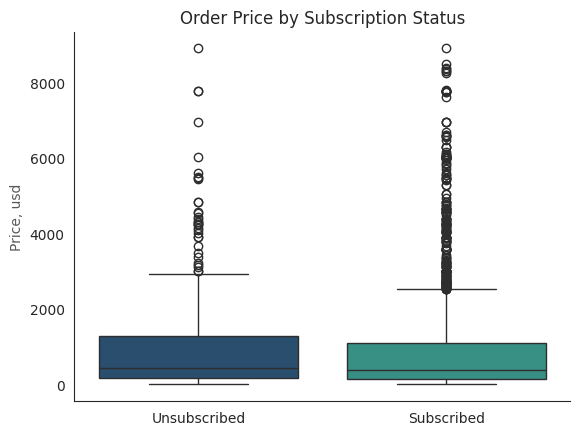

In [ ]:
# Boxplot: price by subscription status / Boxplot: ціна за статусом підписки
registered_orders = orders[orders['subscription_status'].isin(['Subscribed', 'Unsubscribed'])]
sns.boxplot(data=registered_orders,
            x='subscription_status',
            y='price',
            hue='subscription_status',
            legend=False,
            palette=[COLORS['main'], COLORS['second']])
plt.title('Order Price by Subscription Status')
plt.xlabel('')
plt.ylabel('Price, usd', fontsize=10, color=NEUTRAL)
sns.despine()
plt.show()

7.6 There is no statistically significant relationship between subscription status and order price. The median price is 395 usd for Subscribed (2,334 orders) and 450 usd for Unsubscribed (447 orders), and the means are close (921.5 and 965.8 usd). The Mann-Whitney p-value (0.168) is above 0.05, so the observed difference is likely random.

---------

Статистично значущого зв'язку між статусом підписки та ціною товару немає. Медіанна ціна становить 395 usd для Subscribed (2 334 замовлення) і 450 usd для Unsubscribed (447 замовлень), середні значення близькі (921,5 і 965,8 usd). P-value тесту Манна-Вітні (0,168) більше за 0,05, тому виявлена різниця, імовірно, випадкова.

## **8. Statistical analysis of differences between groups**
----------
Статистичний аналіз відмінностей між групами.

**8.1 Analyse the sales figures for each date for registered and guest users.**

------

Проаналізуй продажі за кожну дату зареєстрованих та гостів користувачів.

In [ ]:
# User type: Guest or Registered / Тип користувача
orders['user_type'] = 'Registered'
orders.loc[orders['account_id'] == 'Guest', 'user_type'] = 'Guest'

# Daily revenue by user type / Щоденна виручка за типом користувача
daily_users = orders.pivot_table(index='session_date',
                                 columns='user_type',
                                 values='revenue',
                                 aggfunc='sum').fillna(0) #прибирає 4 остані дні, бо в них немає даних про виторг. Тому для аналіза використовуєсо лише 88 дня

guest_daily = daily_users['Guest']
registered_daily = daily_users['Registered']

print(daily_users.describe().round(0))

user_type     Guest  Registered
count          88.0        88.0
mean       333968.0     29347.0
std         92910.0     10765.0
min        182206.0     11779.0
25%        270486.0     20717.0
50%        316724.0     28048.0
75%        379948.0     35775.0
max        612358.0     68151.0


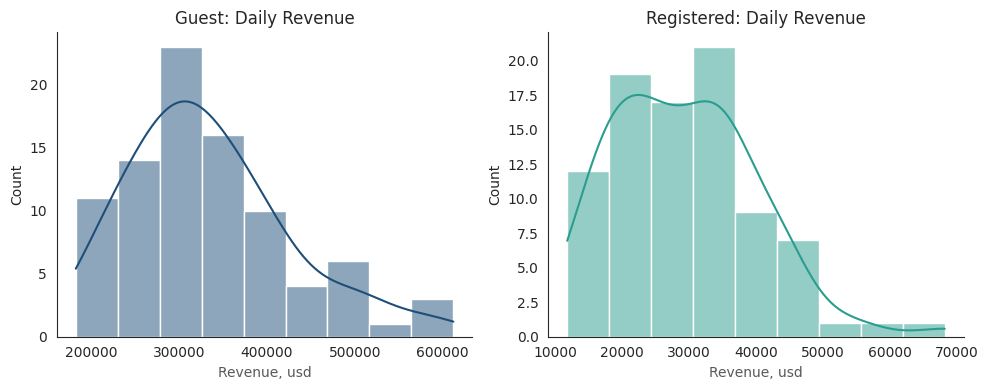

In [ ]:
# Distribution of daily revenue / Розподіл щоденної виручки
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(guest_daily, kde=True, color=COLORS['main'], ax=axes[0])
axes[0].set_title('Guest: Daily Revenue')
axes[0].set_xlabel('Revenue, usd', fontsize=10, color=NEUTRAL)

sns.histplot(registered_daily, kde=True, color=COLORS['second'], ax=axes[1])
axes[1].set_title('Registered: Daily Revenue')
axes[1].set_xlabel('Revenue, usd', fontsize=10, color=NEUTRAL)

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Paired samples check / Перевірка парних вибірок
print('Days:', len(guest_daily), len(registered_daily))  # очікується 88 і 88
print('Same dates:', guest_daily.index.equals(registered_daily.index))

# Normality of paired differences (Shapiro-Wilk) / Нормальність різниць
diff = guest_daily - registered_daily
print('Differences Shapiro p-value:', stats.shapiro(diff)[1])

# Paired test: Wilcoxon signed-rank / Парний тест: Вілкоксон
print('Wilcoxon p-value:', stats.wilcoxon(guest_daily, registered_daily)[1])

Days: 88 88
Same dates: True
Differences Shapiro p-value: 0.0012779540523612212
Wilcoxon p-value: 3.732014234846569e-16


8.1 Daily revenue of Guest users (mean 333,968 usd, median 316,724) is about 11 times higher than that of Registered users (mean 29,347 usd, median 28,048). Both groups have values for the same 88 dates, so the samples are paired by date. The daily differences between the groups are not normally distributed (Shapiro-Wilk p = 0.0013), so the Wilcoxon signed-rank test is used. Its p-value is 3.7e-16, far below 0.05, so the difference is statistically significant (n = 88 days). Guests generate the main share of sales mostly because they account for 92% of all sessions.

---------------

Щоденна виручка Guest (середнє 333 968 usd, медіана 316 724) приблизно в 11 разів вища, ніж у Registered (середнє 29 347 usd, медіана 28 048). Обидві групи мають значення за ті самі 88 дат, тому вибірки парні за датою. Щоденні різниці між групами не мають нормального розподілу (Шапіро-Вілк p = 0,0013), тому використано тест Вілкоксона. Його p-value становить 3,7e-16, що значно менше за 0,05, тож різниця статистично значуща (n = 88 днів). Guest забезпечують основну частину продажів переважно тому, що дають 92% усіх сесій.

**8.2 Проаналізуй кількість сесій за різними каналами трафіку**

------

Analyse the number of sessions across different traffic channels.

In [ ]:
# Daily sessions by traffic channel / Щоденна кількість сесій за каналами трафіку
known = data[data['traffic_channel'] != 'Undefined']
channel_sessions = known.groupby(['session_date', 'traffic_channel'])['session_id'].count().reset_index(name='sessions')

# Wide table (one column per channel) / Широка таблиця (колонка на канал)
channel_wide = channel_sessions.pivot(index='session_date', columns='traffic_channel', values='sessions')
print(channel_wide.describe().round(0))

traffic_channel  Direct  Organic Search  Paid Search  Social Search
count              92.0            92.0         92.0           92.0
mean              885.0          1352.0       1025.0          303.0
std               220.0           337.0        254.0           88.0
min               481.0           733.0        578.0          137.0
25%               744.0          1117.0        860.0          236.0
50%               870.0          1329.0        989.0          308.0
75%              1005.0          1559.0       1172.0          358.0
max              1668.0          2589.0       1959.0          561.0


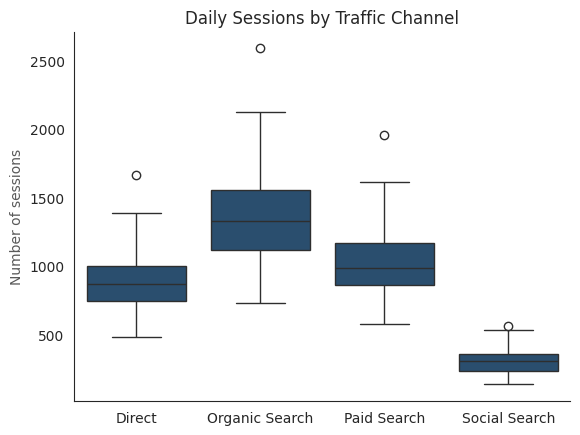

In [ ]:
# Boxplot: daily sessions by channel / Boxplot: щоденні сесії за каналами
sns.boxplot(data=channel_sessions, x='traffic_channel', y='sessions', color=COLORS['main'])
plt.title('Daily Sessions by Traffic Channel')
plt.xlabel('')
plt.ylabel('Number of sessions', fontsize=10, color=NEUTRAL)
sns.despine()
plt.show()

In [ ]:
# Normality of variances / Нормальність дисперсій
print('Direct Shapiro p-value:', stats.shapiro(channel_wide['Direct'])[1])
print('Organic Search Shapiro p-value:', stats.shapiro(channel_wide['Organic Search'])[1])
print('Paid Search Shapiro p-value:', stats.shapiro(channel_wide['Paid Search'])[1])
print('Social Search Shapiro p-value:', stats.shapiro(channel_wide['Social Search'])[1])



Direct Shapiro p-value: 0.034278771626201326
Organic Search Shapiro p-value: 0.012271774671209374
Paid Search Shapiro p-value: 0.010833125972481636
Social Search Shapiro p-value: 0.14127184979117535


In [ ]:
# All groups are normal with equal variances -> ANOVA / Усі групи нормальні з рівними дисперсіями -> ANOVA
print('ANOVA p-value:', stats.f_oneway(channel_wide['Direct'], channel_wide['Organic Search'],
                                       channel_wide['Paid Search'], channel_wide['Social Search'])[1])


ANOVA p-value: 2.425848832599842e-98


8.2 Average daily sessions differ clearly between channels: Organic Search is the highest (1,352), followed by Paid Search (1,025), Direct (885) and Social Search (303). The Shapiro-Wilk test shows non-normal distributions in three of four channels (p = 0.034, 0.012, 0.011; only Social Search is normal, p = 0.141), so strictly the Kruskal-Wallis test is more appropriate than ANOVA. However, the ANOVA p-value (2.4e-98) is far below 0.05 and the boxplots barely overlap, so the differences between channels are statistically significant under either approach.

---------

Середня кількість щоденних сесій помітно різниться між каналами: найбільша в Organic Search (1 352), далі Paid Search (1 025), Direct (885) і Social Search (303). Тест Шапіро-Вілка показує ненормальний розподіл у трьох із чотирьох каналів (p = 0,034, 0,012, 0,011; нормальний лише Social Search, p = 0,141), тому строго коректнішим є тест Краскела-Уолліса, а не ANOVA. Проте p-value ANOVA (2,4e-98) значно менше за 0,05, а boxplot-и майже не перетинаються, тож відмінності між каналами статистично значущі за будь-якого підходу.



**8.3 Is there a statistically significant difference in the proportion of sessions from organic traffic in Europe and America?**

-----

Чи відрізняється статистично доля сесій з органічним трафіком у Європі та Америці?

In [ ]:
# Sessions in Europe and Americas / Сесії в Європі та Америці
europe = data[data['continent'] == 'Europe']
americas = data[data['continent'] == 'Americas']

# Input data for the test: organic sessions and total sessions / Вхідні дані: органічні сесії та всі сесії
organic_europe = (europe['traffic_channel'] == 'Organic Search').sum()
organic_americas = (americas['traffic_channel'] == 'Organic Search').sum()

count = [organic_europe, organic_americas]
nobs = [len(europe), len(americas)]

print('Europe: organic', organic_europe, 'of', len(europe), '|', round(organic_europe / len(europe) * 100, 1), '%')
print('Americas: organic', organic_americas, 'of', len(americas), '|', round(organic_americas / len(americas) * 100, 1), '%')

Europe: organic 23195 of 65135 | 35.6 %
Americas: organic 68671 of 193179 | 35.5 %


In [ ]:
# Z-test for two proportions / Z-тест для двох пропорцій
z, p = proportions_ztest(count, nobs)
print('z-statistic:', round(z, 3))
print('p-value:', p)

z-statistic: 0.29
p-value: 0.7721879690501752


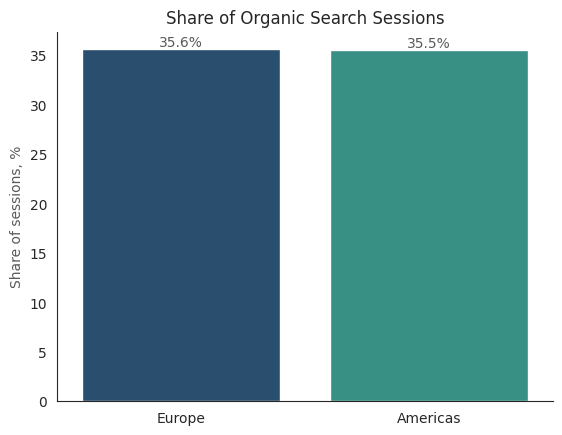

In [ ]:
# Bar chart: share of organic sessions / Стовпчастий графік: частка органічних сесій
share_organic = pd.DataFrame({'continent': ['Europe', 'Americas'],
                              'share': [organic_europe / len(europe) * 100, organic_americas / len(americas) * 100]})

ax = sns.barplot(data=share_organic,
                 x='continent',
                 y='share',
                 hue='continent',
                 legend=False,
                 palette=[COLORS['main'], COLORS['second']])
plt.title('Share of Organic Search Sessions')
plt.xlabel('')
plt.ylabel('Share of sessions, %', fontsize=10, color=NEUTRAL)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1f}%', color=NEUTRAL, fontsize=10)
sns.despine()
plt.show()

8.3 The share of Organic Search sessions is almost identical: 35.6% in Europe (23,195 of 65,135) and 35.5% in the Americas (68,671 of 193,179). The z-test gives z = 0.29 and p = 0.772, which is above 0.05, so there is no statistically significant difference between the two continents.

---------

Частка сесій Organic Search майже однакова: 35,6% у Європі (23 195 із 65 135) і 35,5% в Америці (68 671 із 193 179). Z-тест дає z = 0,29 і p = 0,772, що більше за 0,05, тому статистично значущої різниці між континентами немає.

##General conclusion:
**What the data shows**
We analysed 349,545 web sessions of an online furniture store between November 2020 and January 2021. Only 9.6% of sessions end with an order (33,538 orders), and total revenue is about 32 million usd. The typical order is 445 usd, but a few expensive items push the average up to 953 usd.

**Where the money comes from**
- Markets. The Americas generate 55% of revenue, Asia 24% and Europe 19%. The United States alone gives 44% of sessions and by far the most sales, followed by India, Canada, the United Kingdom and France.
- Products. Sofas & armchairs, Chairs, Beds and Bookcases & shelving units bring about 72% of revenue. Sofas and beds earn a lot because they are expensive, while bookcases are ordered most often but cost less.
- Devices. Desktop gives 59% of revenue and Mobile 39%. Tablet is almost irrelevant (2%).
- Traffic. Organic Search is the biggest source of visits, then Paid Search and Direct. The differences between channels are statistically significant.
- Customers. 92% of sessions come from guests, and only 8% from registered users. About 72% of registered users have verified their email, and 83% are subscribed. We found no significant difference in order price between subscribed and unsubscribed users.

**Patterns in time**
Sales are strongest on weekdays (Tuesday to Thursday) and weakest at weekends. There were peaks in early December and early January, and a drop at the end of December. There is no clear long-term growth. More sessions mean more revenue, but the share of sessions that end with an order stays stable at around 10%.

**What to focus on to grow the business**
- Improve conversion. Nine out of ten visitors leave without buying. Even a small increase in conversion would bring more revenue than additional traffic.
- Push high-value categories. Promote sofas, beds and chairs, and offer bundles that combine popular cheap items (bookcases) with expensive ones.
- Do not depend on one market. The United States is the core, but India and Canada are solid second markets. Europe has potential, because its order value is similar to other regions.
- Turn guests into registered users. Registered users are only 8% of sessions. Discounts or benefits for registration would give the company more contact data and repeat purchases.
- Invest in the best channels and devices. Keep strengthening Organic and Paid Search, and make the desktop and mobile experience as smooth as possible.
- Plan around the calendar. Run campaigns on weekdays and before peak periods, and test offers for weekends, when sales are low.
- Fix data quality. Many values are “Unknown” (language 33%, traffic source 25%), and the device model column mixes browsers and phone models. Better tracking will make future analysis more reliable.
- Limitations. The data covers only three months, so seasonal conclusions are preliminary. Correlations show that metrics move together, not that one causes the other.

##Загальний висновок:
**Що показують дані**
Ми проаналізували 349 545 вебсесій інтернет-магазину меблів за період з листопада 2020 до січня 2021. Лише 9,6% сесій завершуються замовленням (33 538 замовлень), а загальна виручка становить близько 32 млн usd. Типове замовлення коштує 445 usd, але кілька дорогих товарів піднімають середнє до 953 usd.

**Звідки приходять гроші**
- Ринки. Americas дають 55% виручки, Asia 24%, Europe 19%. Лише США формують 44% сесій і найбільше продажів, далі йдуть India, Canada, United Kingdom та France.
- Товари. Sofas & armchairs, Chairs, Beds і Bookcases & shelving units приносять близько 72% виручки. Дивани й ліжка заробляють багато, бо дорогі, а книжкові шафи замовляють найчастіше, але вони дешевші.
- Пристрої. Desktop дає 59% виручки, Mobile 39%. Tablet майже не впливає (2%).
Трафік. Organic Search є найбільшим джерелом відвідувань, далі Paid Search і Direct. Відмінності між каналами статистично значущі.
- Клієнти. 92% сесій припадає на гостей і лише 8% на зареєстрованих користувачів. Близько 72% зареєстрованих підтвердили email, а 83% підписані на розсилку. Значущої різниці в ціні замовлень між підписаними й відписаними немає.

**Закономірності в часі**
Найкращі продажі припадають на будні (вівторок-четвер), найгірші на вихідні. Піки були на початку грудня й на початку січня, а спад наприкінці грудня. Чіткого довгострокового зростання немає. Більше сесій означає більшу виручку, але частка сесій із замовленням залишається стабільною, близько 10%.

**На що звернути увагу для розвитку бізнесу**
- Покращувати конверсію. Дев'ять із десяти відвідувачів йдуть без покупки. Навіть невелике зростання конверсії дасть більше виручки, ніж додатковий трафік.
- Просувати дорогі категорії. Рекламувати дивани, ліжка й стільці та пропонувати набори, які поєднують популярні дешеві товари (книжкові шафи) з дорогими.
- Не залежати від одного ринку. США є основою, але India і Canada вже стали стійкими другими ринками. Europe має потенціал, бо середній чек там такий самий, як в інших регіонах.
- Перетворювати гостей на зареєстрованих користувачів. Зареєстровані становлять лише 8% сесій. Знижки чи бонуси за реєстрацію дадуть більше контактних даних і повторних покупок.
- Інвестувати в найкращі канали та пристрої. Далі розвивати Organic і Paid Search та зробити роботу сайту на desktop і mobile максимально зручною.
- Планувати за календарем. Запускати кампанії в будні та перед піковими періодами, а для вихідних, коли продажі низькі, тестувати окремі пропозиції.
- Покращити якість даних. Багато значень Unknown (мова 33%, джерело трафіку 25%), а стовпець із моделлю пристрою змішує браузери й моделі телефонів. Краще відстеження зробить подальший аналіз надійнішим.
- Обмеження. Дані охоплюють лише три місяці, тому висновки про сезонність попередні. Кореляції показують, що показники змінюються разом, але не доводять, що одне спричиняє інше.

In [ ]:
# 9. To create an analytical dashboard in Tableau Public. Convert the database to CSV format and download it / Для створення аналітичного дашборду у Tableau Public. Перетворюємо базу даних у csv формат та скачуємо
# Download dataframe for working with it in Tableau / Скачуємо датафрейм для роботи з ним у Tableau

#data.to_csv('data_final.csv', index=False)
#files.download('data_final.csv')

A link to the dashboard on the Tableau / Посилання на дашборд у Tableau
https://public.tableau.com/views/OnlineFurnitureStoreSalesWebSessionsDashboard/OnlineFurnitureStoreSalesWebSessionsDashboard?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link